# Preventing Cascading Failures in Urban Drainage Networks Using Graph Theory
Stage 5 implementation (Google Colab ready). Run the cells **top to bottom**.

**Important:** the network is synthetic and the flow routing is a simplified steady-state approximation, not a validated hydraulic simulator. All parameters are illustrative assumptions.

Sections: 1 Setup, 2 Modules, 3 Validation tests, 4 Example figures, 5 Experiments (Stage 6), 6 Paired comparison.

## 1. Setup

In [1]:
import os, sys
os.makedirs('drainage/results', exist_ok=True)
os.chdir('drainage')
sys.path.insert(0, os.getcwd())
import numpy, pandas, networkx, scipy, matplotlib
print('numpy', numpy.__version__, '| networkx', networkx.__version__)

numpy 2.3.3 | networkx 3.6


## 2. Modules (each cell writes one file)

In [2]:
%%writefile cascade.py
"""Flow routing and iterative cascading-failure engine.

APPROXIMATION: steady-state routing on a gravity-oriented DAG. Not a hydraulic simulator.
Rule: a node sends its total inflow q_v only along surviving pipes whose head can still
reach an outlet, split in proportion to the pipes' routing weights w_e. Capacity is NOT
enforced during routing, so L_e > C_e (overload) can occur and triggers failure.
"""
import numpy as np


def route(net, alive, w, theta):
    """Return (load per pipe, unmet demand, reach mask, delivered flow)."""
    head, out, outl, dem = net.head_l, net.out_l, net.outl_l, net.dem_l
    reach = outl[:]
    for v in net.order_rev:                      # low elevation first
        if not reach[v]:
            for e in out[v]:
                if alive[e] and reach[head[e]]:
                    reach[v] = True
                    break
    inflow = [0.0] * net.n
    load = [0.0] * net.m
    unmet = delivered = 0.0
    for v in net.order:                          # high elevation first
        q = theta * dem[v] + inflow[v]
        if outl[v]:
            delivered += q
            continue
        if not reach[v]:
            unmet += theta * dem[v]
            continue
        elig = [e for e in out[v] if alive[e] and reach[head[e]]]
        tot = sum(w[e] for e in elig)
        for e in elig:
            f = q * w[e] / tot
            load[e] = f
            inflow[head[e]] += f
    return np.array(load), unmet, np.array(reach), delivered


def cascade(net, cap, w, theta, F0, record=False):
    """Iterate: route -> mark overloaded pipes failed -> repeat until stable.
    Failures are simultaneous within a round. F only grows, so it terminates."""
    failed = F0.copy()
    history = [failed.copy()] if record else None
    steps = 0
    wl = list(w)
    while True:
        alive = (~failed).tolist()
        load, unmet, reach, delivered = route(net, alive, wl, theta)
        over = (~failed) & (load > cap * (1 + 1e-9))
        if not over.any():
            break
        failed |= over
        steps += 1
        if record:
            history.append(failed.copy())
    return dict(failed=failed, load=load, unmet=unmet, reach=reach,
                delivered=delivered, steps=steps, history=history)

Overwriting cascade.py


In [3]:
%%writefile network.py
"""Synthetic drainage network generator (units: L/s, m).
NOT a validated representation of any real city's drainage infrastructure."""
import numpy as np
from cascade import route


class Network:
    def __init__(self, **kw):
        self.__dict__.update(kw)
        self.m = len(self.tail)
        self.tail_l, self.head_l = self.tail.tolist(), self.head.tolist()
        self.outl_l = self.outlets.tolist()
        self.dem_l = self.demand0.tolist()
        self.order = np.argsort(-self.z).tolist()      # edges go strictly downhill
        self.order_rev = self.order[::-1]
        self.out_l = [[] for _ in range(self.n)]
        for e, (u, v) in enumerate(zip(self.tail_l, self.head_l)):
            self.out_l[u].append(e)
        nb = [set() for _ in range(self.n)]
        for u, v in zip(self.tail_l, self.head_l):
            nb[u].add(v); nb[v].add(u)
        self.nbr_l = [sorted(s) for s in nb]

    def set_scale(self, s):
        """Capacity C_e = max((1 + s*alpha_e) * L0_e, cmin); alpha_e ~ U(0.5, 1.5)."""
        self.scale = s
        self.cap0 = np.maximum((1 + s * self.alpha_raw) * self.load0, self.cmin)


def build_network(seed, rows=7, cols=8, n_outlets=3, thin=0.10, inlet_frac=0.6,
                  scale=0.3, cmin=0.5):
    rng = np.random.default_rng(seed)
    n = rows * cols
    r_idx, c_idx = np.arange(n) // cols, np.arange(n) % cols
    pos = np.c_[c_idx, -r_idx].astype(float)
    z = (rows - 1 - r_idx) * 10.0 + rng.normal(0, 3, n)
    outl = rng.choice(np.arange((rows - 1) * cols, n), n_outlets, replace=False)
    outlets = np.zeros(n, bool); outlets[outl] = True
    z[outl] -= 15
    adj = [(r * cols + c, r * cols + c + 1) for r in range(rows) for c in range(cols - 1)]
    adj += [(r * cols + c, (r + 1) * cols + c) for r in range(rows - 1) for c in range(cols)]
    nbrs = [[] for _ in range(n)]
    for a, b in adj:
        nbrs[a].append(b); nbrs[b].append(a)
    for _ in range(200):                                # fill pits so every node drains
        changed = False
        for v in range(n):
            if not outlets[v] and all(z[w] >= z[v] for w in nbrs[v]):
                z[v] = min(z[w] for w in nbrs[v]) + rng.uniform(0.1, 1.0)
                changed = True
        if not changed:
            break
    edges = []
    for a, b in adj:
        u, v = (a, b) if z[a] > z[b] else (b, a)
        if not outlets[u]:
            edges.append((u, v))
    out_deg = np.bincount([u for u, _ in edges], minlength=n)
    remove, target = set(), int(thin * len(edges))
    for i in rng.permutation(len(edges)):               # thin, keeping out-degree >= 1
        if len(remove) >= target:
            break
        u = edges[i][0]
        if out_deg[u] > 1:
            remove.add(i); out_deg[u] -= 1
    edges = [e for i, e in enumerate(edges) if i not in remove]
    tail = np.array([u for u, _ in edges]); head = np.array([v for _, v in edges])
    m = len(edges)
    in_deg = np.bincount(head, minlength=n)
    inlet = ((rng.random(n) < inlet_frac) | (in_deg == 0)) & ~outlets
    demand0 = np.where(inlet, 2.0 * rng.lognormal(0, 0.5, n), 0.0)
    net = Network(seed=seed, n=n, pos=pos, z=z, outlets=outlets, demand0=demand0,
                  tail=tail, head=head, length=rng.uniform(50, 150, m),
                  g=rng.lognormal(0, 0.4, m), alpha_raw=rng.uniform(0.5, 1.5, m),
                  risk=rng.beta(2, 30, m), cmin=cmin)
    load, unmet, reach, _ = route(net, [True] * m, net.g.tolist(), 1.0)
    assert unmet == 0 and reach.all(), "every node must reach an outlet"
    net.load0 = load
    net.set_scale(scale)
    return net

Overwriting network.py


In [4]:
%%writefile centrality.py
"""Structural importance measures b_e and comparison measures."""
import networkx as nx
import numpy as np
from cascade import route


def to_digraph(net):
    G = nx.DiGraph()
    G.add_nodes_from(range(net.n))
    for e, (u, v) in enumerate(zip(net.tail_l, net.head_l)):
        G.add_edge(u, v, eid=e, length=float(net.length[e]))
    return G


def edge_betweenness_subset(net):
    """Directed edge betweenness, sources = demand nodes, targets = outlets."""
    G = to_digraph(net)
    src = [v for v in range(net.n) if net.demand0[v] > 0]
    tgt = [v for v in range(net.n) if net.outlets[v]]
    bc = nx.edge_betweenness_centrality_subset(G, sources=src, targets=tgt,
                                               normalized=True, weight="length")
    b = np.zeros(net.m)
    for (u, v), val in bc.items():
        b[G[u][v]["eid"]] = val
    return b


def catchment(net):
    """Demand of all nodes upstream of (and including) the pipe's tail."""
    G = to_digraph(net)
    up = {v: net.demand0[v] + sum(net.demand0[a] for a in nx.ancestors(G, v)) for v in range(net.n)}
    return np.array([up[u] for u in net.tail_l])


def oracle(net):
    """Unmet-demand fraction if this single pipe fails (benchmark, not a deployable score)."""
    out = np.zeros(net.m)
    for e in range(net.m):
        alive = [True] * net.m; alive[e] = False
        _, unmet, _, _ = route(net, alive, net.g.tolist(), 1.0)
        out[e] = unmet / net.demand0.sum()
    return out


def utilisation(net):
    return net.load0 / net.cap0


MEASURES = {"bet": edge_betweenness_subset, "catch": catchment, "oracle": oracle}

Overwriting centrality.py


In [5]:
%%writefile strategies.py
"""Priority scores and pipe selection for strategies A-E."""
import numpy as np


def minmax(x):
    lo, hi = float(np.min(x)), float(np.max(x))
    return (x - lo) / (hi - lo) if hi > lo else np.zeros_like(x, float)


def rank01(x):
    return np.argsort(np.argsort(x, kind="stable"), kind="stable") / max(len(x) - 1, 1)


def top_k(score, K):
    return np.argsort(-score, kind="stable")[:K]


def priority(r_obs, b, lam, norm="minmax"):
    f = minmax if norm == "minmax" else rank01
    return lam * f(r_obs) + (1 - lam) * f(b)


def select(name, K, r_obs, b, util, rng, lam=None, norm="minmax"):
    if name == "D_none":
        return np.array([], int)
    if name == "A_risk":
        return top_k(r_obs, K)
    if name == "B_graph":
        return top_k(priority(r_obs, b, lam, norm), K)
    if name == "C_random":
        return rng.choice(len(r_obs), K, replace=False)
    if name == "E_load":
        return top_k(util, K)
    raise ValueError(name)

Overwriting strategies.py


In [6]:
%%writefile evaluate.py
"""Evaluation metrics and paired statistics."""
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon


def largest_cut_region(net, reach):
    cut = [v for v in range(net.n) if not reach[v] and not net.outl_l[v]]
    seen, best = set(), 0
    for s in cut:
        if s in seen:
            continue
        stack, size = [s], 0
        seen.add(s)
        while stack:
            v = stack.pop(); size += 1
            for w in net.nbr_l[v]:
                if w not in seen and not reach[w] and not net.outl_l[w]:
                    seen.add(w); stack.append(w)
        best = max(best, size)
    return best


def metrics(net, res, F0, theta):
    failed = res["failed"]
    nf = int(failed.sum())
    tot = theta * net.demand0.sum()
    return dict(Rf=nf / net.m, secondary=nf - int(F0.sum()),
                RC=net.cap0[~failed].sum() / net.cap0.sum(),     # uses original capacities
                U=res["unmet"] / tot, delivered=res["delivered"] / tot,
                region=largest_cut_region(net, res["reach"]), steps=res["steps"])


def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def paired_table(df, ref, target, metric, keys=("theta", "budget"), n_boot=2000, seed=0):
    """Paired comparison. diff = ref - target (positive means target is better, lower metric)."""
    piv = df[df.strategy.isin([ref, target])].pivot_table(
        index=list(keys) + ["net", "trial"], columns="strategy", values=metric).reset_index()
    rng = np.random.default_rng(seed)
    rows = []
    for k, g in piv.groupby(list(keys)):
        d = (g[ref] - g[target]).to_numpy()
        boots = rng.choice(d, (n_boot, len(d))).mean(1)
        p = 1.0 if np.allclose(d, 0) else wilcoxon(d).pvalue
        mr = g[ref].mean()
        rows.append(dict(zip(keys, k if isinstance(k, tuple) else (k,)),
                         mean_ref=mr, mean_target=g[target].mean(), mean_diff=d.mean(),
                         ci_lo=np.percentile(boots, 2.5), ci_hi=np.percentile(boots, 97.5),
                         reduction_pct=100 * d.mean() / mr if mr > 0 else np.nan,
                         p_raw=p, n=len(d)))
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out.p_raw.values)
    return out

Overwriting evaluate.py


In [7]:
%%writefile run_experiments.py
"""Experiment runner. Common random numbers: the same U_e per (network, trial) for all strategies."""
import argparse, os, time
import numpy as np
import pandas as pd
from network import build_network
from cascade import cascade
from centrality import MEASURES, utilisation
from strategies import select
from evaluate import metrics

K_REINF, DELTA = 1.5, 0.5          # capacity multiplier, risk reduction (identical for all strategies)


def calibrate_scale(net, target=0.10, trials=40, seed=12345):
    """Choose capacity margin so Strategy D fails ~target of pipes at theta=1. D only."""
    rng = np.random.default_rng(seed)
    U = rng.random((trials, net.m))
    best, best_gap = None, 9
    for s in np.geomspace(0.1, 8.0, 30):
        net.set_scale(s); rf = []
        for t in range(trials):
            F0 = U[t] < np.minimum(1, net.risk)
            rf.append(cascade(net, net.cap0, net.g, 1.0, F0)["failed"].mean())
        gap = abs(np.mean(rf) - target)
        if gap < best_gap:
            best, best_gap = s, gap
    net.set_scale(best)
    net.calib_gap = best_gap
    return best


def apply_risk_correlation(net, b, rho):
    """True risk = (1-rho)*independent + rho*(same values re-assigned in order of b)."""
    r_ind = net.risk.copy()
    r_sorted = np.sort(r_ind)[np.argsort(np.argsort(b, kind="stable"), kind="stable")]
    net.risk = (1 - rho) * r_ind + rho * r_sorted


def run_network(net_seed, thetas, budgets, trials, lams, n_random=30, sigma=0.0, rho=0.0,
                base_seed=2026, offset=0, scale=None, measure="bet", norm="minmax",
                weight_follows_capacity=True):
    net = build_network(net_seed)
    s = calibrate_scale(net) if scale is None else (net.set_scale(scale) or scale)
    b = MEASURES[measure](net)
    if rho > 0:
        apply_risk_correlation(net, b, rho)
    util = utilisation(net)
    rows = []
    for t in range(trials):
        rng = np.random.default_rng([base_seed, net_seed, offset + t])
        Ue = rng.random(net.m)                                   # common random numbers
        r_obs = net.risk * np.exp(sigma * rng.standard_normal(net.m)) if sigma > 0 else net.risk
        for bud in budgets:
            K = int(np.ceil(bud * net.m))
            sel = {"A_risk": select("A_risk", K, r_obs, b, util, rng),
                   "D_none": select("D_none", K, r_obs, b, util, rng),
                   "E_load": select("E_load", K, r_obs, b, util, rng)}
            for lam in lams:
                sel[f"B_lam{lam:.2f}"] = select("B_graph", K, r_obs, b, util, rng, lam, norm)
            rand = [select("C_random", K, r_obs, b, util, rng) for _ in range(n_random)]
            for theta in thetas:
                def run(idx, name):
                    mask = np.zeros(net.m, bool); mask[idx] = True
                    cap = net.cap0 * np.where(mask, K_REINF, 1.0)
                    w = net.g * np.where(mask, K_REINF, 1.0) if weight_follows_capacity else net.g
                    p = np.minimum(1.0, theta * net.risk * (1 - DELTA * mask))
                    F0 = Ue < p
                    t0 = time.perf_counter()
                    res = cascade(net, cap, w, theta, F0)
                    m = metrics(net, res, F0, theta)
                    m["runtime_ms"] = 1000 * (time.perf_counter() - t0)
                    return m
                for name, idx in sel.items():
                    rows.append(dict(net=net_seed, theta=theta, budget=bud, trial=offset + t,
                                     strategy=name, **run(idx, name)))
                ms = [run(idx, "C") for idx in rand]
                avg = {k: float(np.mean([m[k] for m in ms])) for k in ms[0]}
                rows.append(dict(net=net_seed, theta=theta, budget=bud, trial=offset + t,
                                 strategy="C_random", **avg))
    df = pd.DataFrame(rows)
    df["scale"] = s
    df["sigma"], df["rho"] = sigma, rho
    return df


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--net-seeds", type=int, nargs="+", default=[101, 102, 103, 104, 105])
    ap.add_argument("--trials", type=int, default=100)
    ap.add_argument("--thetas", type=float, nargs="+", default=[0.7, 1.0, 1.3, 1.6])
    ap.add_argument("--budgets", type=float, nargs="+", default=[0.05, 0.10, 0.20])
    ap.add_argument("--lams", type=float, nargs="+", default=[0.0, 0.25, 0.5, 0.75])
    ap.add_argument("--n-random", type=int, default=30)
    ap.add_argument("--sigma", type=float, default=0.0)
    ap.add_argument("--rho", type=float, default=0.0)
    ap.add_argument("--measure", default="bet", choices=list(MEASURES))
    ap.add_argument("--split", default="test", choices=["tune", "test"])
    ap.add_argument("--out", default="results/results.csv")
    a = ap.parse_args()
    os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
    off = 0 if a.split == "tune" else 1000
    t0 = time.time()
    dfs = [run_network(s, a.thetas, a.budgets, a.trials, a.lams, a.n_random, a.sigma, a.rho,
                       offset=off, measure=a.measure) for s in a.net_seeds]
    pd.concat(dfs).to_csv(a.out, index=False)
    print(f"saved {a.out} in {time.time() - t0:.1f}s")

Overwriting run_experiments.py


In [8]:
%%writefile plots.py
"""Network, critical-pipe and cascade-example figures."""
import numpy as np
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from cascade import cascade
from centrality import MEASURES
from strategies import priority, top_k


def draw(net, ax, width=None, reinforced=None, failed=None, title=""):
    reinforced = np.zeros(net.m, bool) if reinforced is None else reinforced
    failed = np.zeros(net.m, bool) if failed is None else failed
    width = np.full(net.m, 1.2) if width is None else width
    for e, (u, v) in enumerate(zip(net.tail_l, net.head_l)):
        col = "#d62728" if failed[e] else ("#1f77b4" if reinforced[e] else "#8a8a8a")
        ax.annotate("", xy=net.pos[v], xytext=net.pos[u], zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=width[e],
                                    ls="--" if failed[e] else "-", shrinkA=6, shrinkB=6, mutation_scale=9))
    inl = net.demand0 > 0
    ax.scatter(*net.pos[inl].T, s=40, c="#f2a54a", zorder=2, edgecolor="k", lw=.4)
    ax.scatter(*net.pos[~inl & ~net.outlets].T, s=22, c="white", zorder=2, edgecolor="k", lw=.4)
    ax.scatter(*net.pos[net.outlets].T, s=90, marker="s", c="#2ca02c", zorder=3, edgecolor="k")
    ax.set_title(title, fontsize=10); ax.axis("off")


def make_figures(net, outdir, theta=1.6, budget=0.10, seed=3):
    b = MEASURES["bet"](net)
    K = int(np.ceil(budget * net.m))
    S = priority(net.risk, b, 0.5)
    crit = np.zeros(net.m, bool); crit[top_k(S, K)] = True
    fig, ax = plt.subplots(figsize=(7, 6.5))
    draw(net, ax, title="Synthetic drainage network (orange: inlets, green squares: outlets)")
    fig.savefig(f"{outdir}/fig1_network.png", dpi=200, bbox_inches="tight"); plt.close(fig)
    fig, ax = plt.subplots(figsize=(7, 6.5))
    draw(net, ax, width=0.8 + 4 * S / S.max(), reinforced=crit,
         title=f"Strategy B (lambda=0.5): top {K} pipes (blue); width = priority score")
    fig.savefig(f"{outdir}/fig2_critical_pipes.png", dpi=200, bbox_inches="tight"); plt.close(fig)
    rng = np.random.default_rng(seed); best = None
    for _ in range(200):                                  # pick an illustrative multi-step cascade
        F0 = rng.random(net.m) < np.minimum(1, theta * net.risk)
        r = cascade(net, net.cap0, net.g, theta, F0, record=True)
        if best is None or r["steps"] > best["steps"]:
            best = r
    h = best["history"][:4]
    fig, axs = plt.subplots(1, len(h), figsize=(4 * len(h), 4.2))
    for i, (a, f) in enumerate(zip(np.atleast_1d(axs), h)):
        draw(net, a, failed=f, title=f"{'Initial failures' if i == 0 else f'Round {i}'}: {int(f.sum())} failed")
    fig.suptitle(f"Failure propagation example (theta={theta}, no intervention)")
    fig.savefig(f"{outdir}/fig3_cascade_example.png", dpi=170, bbox_inches="tight"); plt.close(fig)

Overwriting plots.py


In [9]:
%%writefile tests.py
"""Validation tests (Stage 4 list). Run: python tests.py"""
import numpy as np
import networkx as nx
from network import build_network
from cascade import route, cascade
from centrality import to_digraph, MEASURES, utilisation
from strategies import select
from run_experiments import run_network, calibrate_scale

ok = lambda name, cond, info="": print(f"[{'PASS' if cond else 'FAIL'}] {name} {info}") or cond
res = []
nets = [build_network(s) for s in (101, 102, 103, 104, 105)]
for net in nets:
    calibrate_scale(net)
n = nets[0]

gaps=[x.calib_gap for x in nets]
res.append(ok("0 calibration: D failure rate at theta=1 within 0.02 of 0.10", max(gaps)<0.02, f"gaps={[round(g,3) for g in gaps]}, scales={[round(x.scale,2) for x in nets]}"))
res.append(ok("1 DAG and all nodes reach an outlet",
              all(nx.is_directed_acyclic_graph(to_digraph(x)) for x in nets)
              and all(route(x, [True] * x.m, x.g.tolist(), 1.0)[2].all() for x in nets),
              f"pipes={[x.m for x in nets]}"))
rng = np.random.default_rng(0); worst = 0
for x in nets:
    for _ in range(20):
        alive = (rng.random(x.m) > 0.15).tolist(); th = rng.choice([0.7, 1.3, 1.6])
        _, unmet, _, deliv = route(x, alive, x.g.tolist(), th)
        worst = max(worst, abs(unmet + deliv - th * x.demand0.sum()))
res.append(ok("2 flow conservation (delivered + unmet = demand)", worst < 1e-9, f"max err={worst:.2e}"))
over0 = max((route(x, [True] * x.m, x.g.tolist(), 1.0)[0] > x.cap0 * (1 + 1e-9)).sum() for x in nets)
res.append(ok("3 no overload at theta=1, no failures, no reinforcement", over0 == 0, f"overloads={over0}"))
r = cascade(n, n.cap0, n.g, 1.6, rng.random(n.m) < 0.1, record=True)
mono = all((r["history"][i] <= r["history"][i + 1]).all() for i in range(len(r["history"]) - 1))
res.append(ok("4 cascade terminates, failed set only grows", mono and r["steps"] <= n.m,
              f"steps={r['steps']}"))
b = MEASURES["bet"](n); u = utilisation(n); rr = np.random.default_rng(1)
same = all((select("A_risk", K, n.risk, b, u, rr) == select("B_graph", K, n.risk, b, u, rr, 1.0)).all()
           for K in (5, 9, 18))
res.append(ok("5 B at lambda=1 selects same pipes as A", same))
kw = dict(thetas=[1.3], budgets=[0.1], trials=5, lams=[0.5], n_random=3)
d1, d2 = run_network(101, **kw), run_network(101, **kw)
res.append(ok("6 same seed gives identical results",
              d1.drop(columns="runtime_ms").equals(d2.drop(columns="runtime_ms"))))
d = run_network(101, thetas=[0.7, 1.0, 1.3, 1.6], budgets=[0.10], trials=30, lams=[0.5], n_random=5)
mean = d.groupby(["theta", "strategy"]).Rf.mean().unstack()
print(mean.round(4).to_string())
res.append(ok("7 (soft) mean R_f of D >= A, B, E at theta>=1.3",
              bool((mean.loc[[1.3, 1.6], "D_none"] >= mean.loc[[1.3, 1.6], ["A_risk", "B_lam0.50", "E_load"]].max(axis=1) - 1e-9).all())))
print(f"\n{sum(res)}/{len(res)} passed")

Overwriting tests.py


## 3. Validation tests (all should print PASS)

In [10]:
!python tests.py

[PASS] 0 calibration: D failure rate at theta=1 within 0.02 of 0.10 gaps=[np.float64(0.001), np.float64(0.003), np.float64(0.005), np.float64(0.007), np.float64(0.0)], scales=[np.float64(2.78), np.float64(1.77), np.float64(2.78), np.float64(2.05), np.float64(1.52)]
[PASS] 1 DAG and all nodes reach an outlet pipes=[87, 88, 87, 86, 87]
[PASS] 2 flow conservation (delivered + unmet = demand) max err=2.84e-14
[PASS] 3 no overload at theta=1, no failures, no reinforcement overloads=0
[PASS] 4 cascade terminates, failed set only grows steps=1
[PASS] 5 B at lambda=1 selects same pipes as A 
[PASS] 6 same seed gives identical results 
strategy  A_risk  B_lam0.50  C_random  D_none  E_load
theta                                                
0.7       0.0456     0.0444    0.0454  0.0475  0.0406
1.0       0.0828     0.0828    0.0911  0.0981  0.0828
1.3       0.1238     0.1368    0.1473  0.1617  0.1375
1.6       0.1900     0.2061    0.2217  0.2395  0.2138
[PASS] 7 (soft) mean R_f of D >= A, B, E 

## 4. Example figures (network, critical pipes, cascade example)

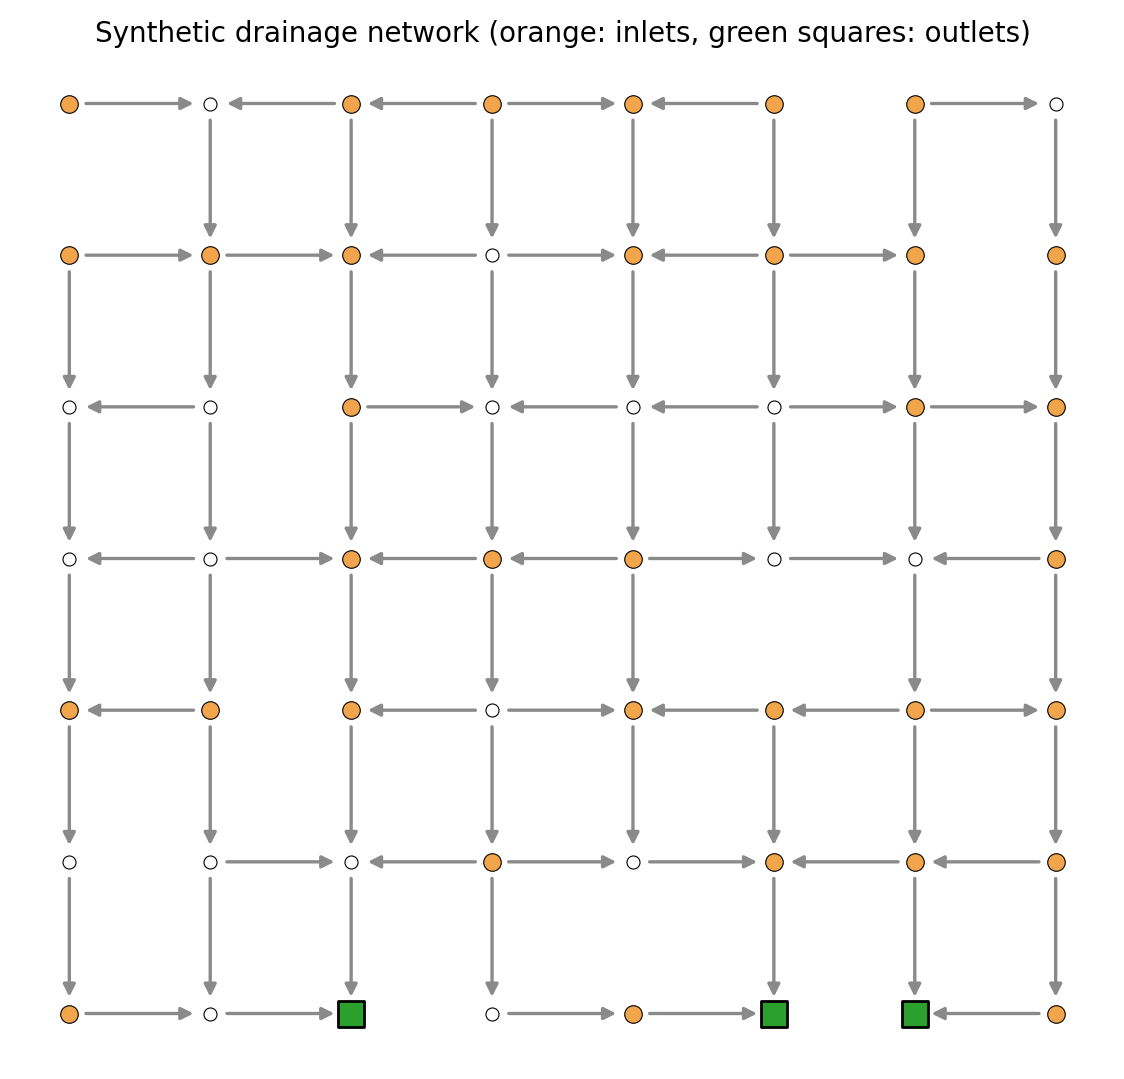

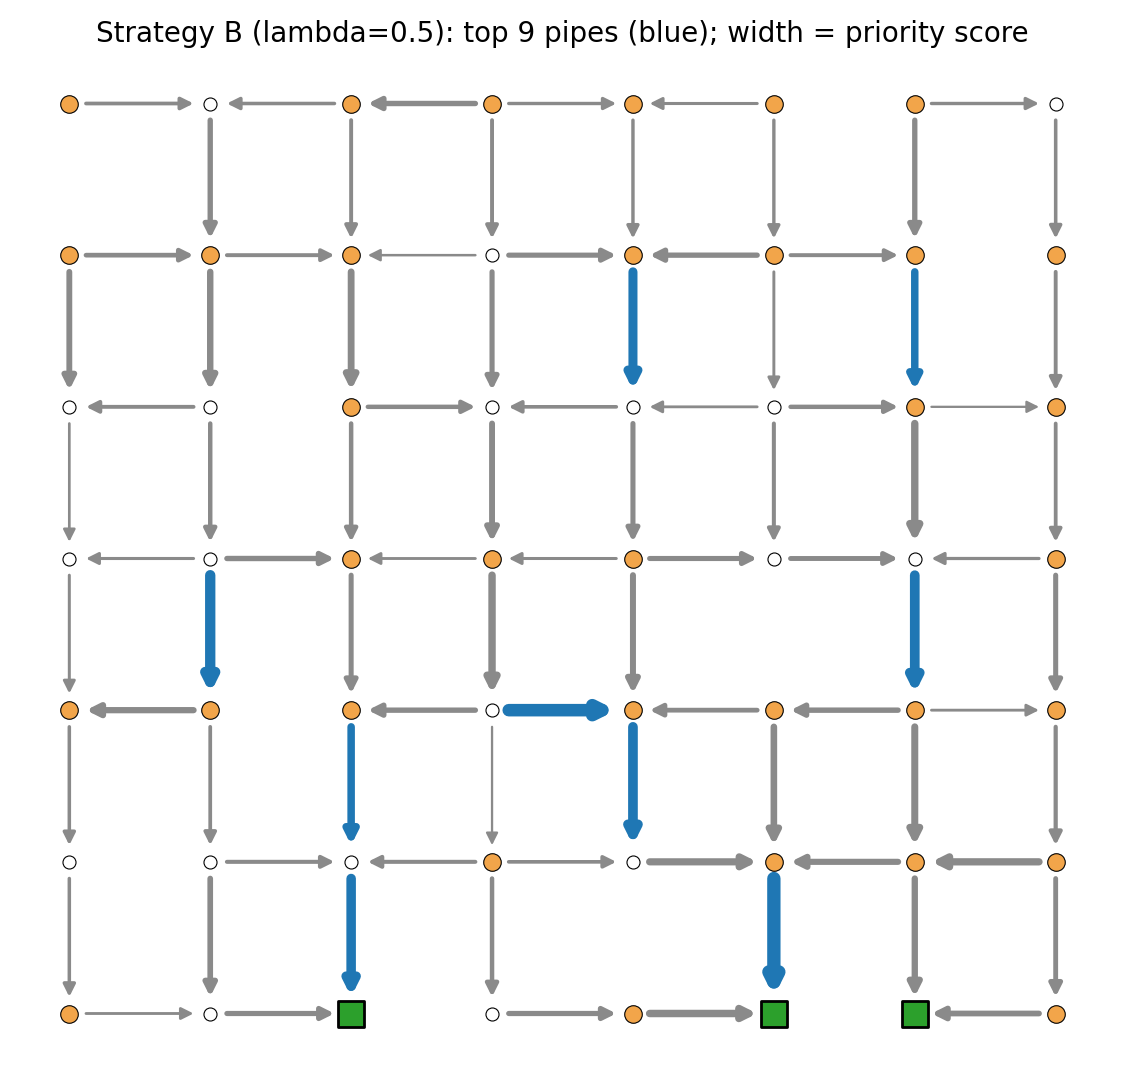

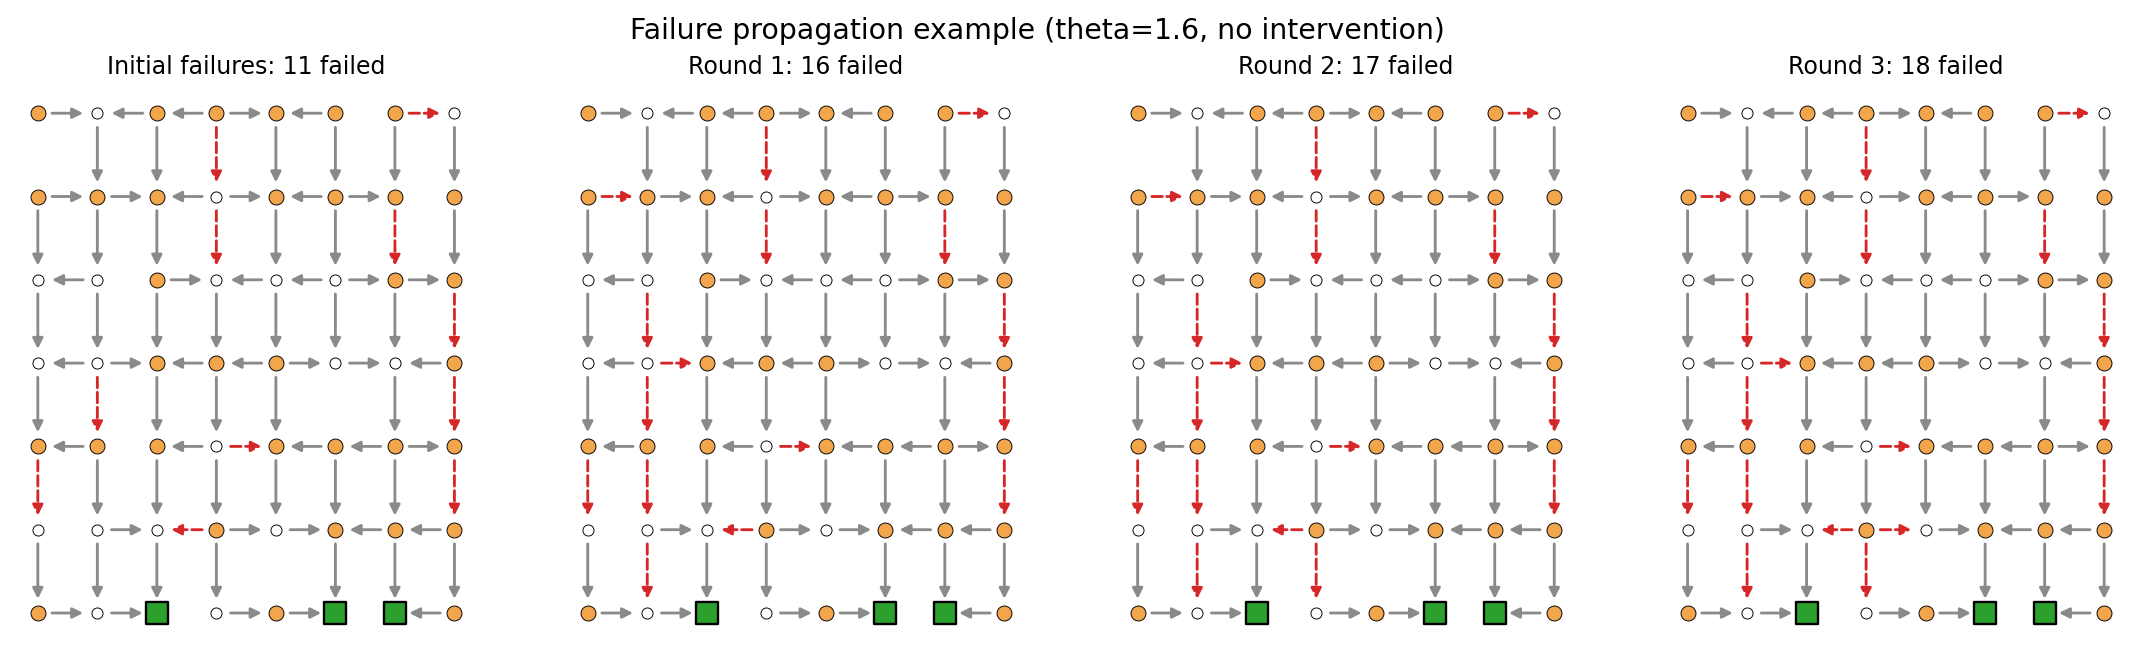

In [11]:
from network import build_network
from run_experiments import calibrate_scale
from plots import make_figures
from IPython.display import Image, display
net = build_network(101); calibrate_scale(net); make_figures(net, 'results')
for f in ['fig1_network','fig2_critical_pipes','fig3_cascade_example']:
    display(Image(f'results/{f}.png'))

## 5. Experiments (Stage 6)
Tune split (seeds 0-999) chooses lambda*; the test split (1000+) gives the headline comparison. Each command takes about 1 minute. Lower `--trials` for a quick check.

In [12]:
!python run_experiments.py --split tune --trials 100 --out results/tune.csv
!python run_experiments.py --split test --trials 100 --out results/test.csv

saved results/tune.csv in 157.7s
saved results/test.csv in 131.0s


Stress tests and ablations: noisy risk estimates, risk correlated with structure, alternative importance measures.

In [13]:
!python run_experiments.py --split test --sigma 0.5 --out results/noise05.csv
!python run_experiments.py --split test --sigma 1.0 --out results/noise10.csv
!python run_experiments.py --split test --rho 0.5 --out results/corr05.csv
!python run_experiments.py --split test --rho 1.0 --out results/corr10.csv
!python run_experiments.py --split test --measure catch --out results/catch.csv
!python run_experiments.py --split test --measure oracle --out results/oracle.csv

saved results/noise05.csv in 125.7s
saved results/noise10.csv in 128.2s
saved results/corr05.csv in 126.4s
saved results/corr10.csv in 129.5s
saved results/catch.csv in 128.9s
saved results/oracle.csv in 130.2s


## 6. Analysis: tables and colour-blind-safe figures (Okabe-Ito palette)

In [14]:
%%writefile analysis.py
"""Stage 6 analysis: tables + colour-blind-safe figures with data-driven takeaway titles.
Palette: Okabe-Ito. Run after run_experiments.py has produced results/*.csv."""
import os
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.stats import spearmanr
from evaluate import paired_table
from network import build_network
from centrality import MEASURES, utilisation
from run_experiments import calibrate_scale
from strategies import priority, top_k

R, FIG, TAB = "results", "results/figs", "results/tables"
os.makedirs(FIG, exist_ok=True); os.makedirs(TAB, exist_ok=True)
PAL = {"A_risk": "#0072B2", "B": "#D55E00", "C_random": "#8C8C8C", "D_none": "#222222", "E_load": "#009E73"}
MRK = {"A_risk": "o", "B": "s", "C_random": "^", "D_none": "X", "E_load": "D"}
ORDER = ["D_none", "C_random", "A_risk", "E_load", "B"]
GOOD, TIE, BAD, MIX = "#009E73", "#BDBDBD", "#D55E00", "#E69F00"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "figure.dpi": 110, "savefig.dpi": 200})

tune, test = pd.read_csv(f"{R}/tune.csv"), pd.read_csv(f"{R}/test.csv")
bn = [s for s in tune.strategy.unique() if s.startswith("B_")]
LS = tune[tune.strategy.isin(bn)].groupby("strategy").Rf.mean().idxmin()      # lambda* from TUNE only
LAM = float(LS.split("lam")[1])
LAB = {"A_risk": "A  Risk-based", "B": f"B  Graph-based (λ*={LAM:g})", "C_random": "C  Random",
       "D_none": "D  No intervention", "E_load": "E  Load-based"}
THETAS, BUDS = sorted(test.theta.unique()), sorted(test.budget.unique())


def tag(df):
    d = df.copy(); d["S"] = np.where(d.strategy == LS, "B", d.strategy)
    return d[d.S.isin(ORDER)]


T = tag(test)


def summ(df, metric, by):
    g = df.groupby(by)[metric].agg(["mean", "std", "count"]).reset_index()
    g["ci"] = 1.96 * g["std"] / np.sqrt(g["count"]); return g


def head(fig, title, sub, foot):
    fig.suptitle(title, x=0.01, y=0.99, ha="left", fontsize=12.5, fontweight="bold")
    fig.text(0.01, 0.925, sub, ha="left", fontsize=9.5, color="#444")
    fig.text(0.01, 0.005, foot, ha="left", fontsize=8.6, color="#555", style="italic")


def legend(fig, y=0.885):
    hs = [plt.Line2D([], [], color=PAL[s], marker=MRK[s], lw=2, label=LAB[s]) for s in ORDER[::-1]]
    fig.legend(handles=hs, loc="upper left", bbox_to_anchor=(0.01, y), ncol=5, frameon=False, fontsize=9)


# ---------- paired statistics (B* vs A, B* vs E) ----------
PA = {m: paired_table(T.assign(strategy=T.S), "A_risk", "B", m) for m in ["Rf", "U", "secondary", "region"]}
PE = {m: paired_table(T.assign(strategy=T.S), "E_load", "B", m) for m in ["Rf", "U"]}
PA["RC"] = paired_table(T.assign(strategy=T.S), "B", "A_risk", "RC")   # RC: higher is better, so ref=B
for k, v in {**{f"B_vs_A_{m}": PA[m] for m in PA}, **{f"B_vs_E_{m}": PE[m] for m in PE}}.items():
    v.round(5).to_csv(f"{TAB}/paired_{k}.csv", index=False)


def classify(p):
    sig = p.p_holm < .05
    return int((sig & (p.mean_diff > 0)).sum()), int((sig & (p.mean_diff < 0)).sum()), len(p)


def phrase(p, what="R_f"):
    b, w, n = classify(p)
    if b == 0 and w == 0: return f"B* shows no significant {what} difference from A in any of {n} cells"
    if w == 0: return f"B* significantly lowers {what} vs A in {b} of {n} cells, never worse"
    return f"B* lowers {what} in {b} cells but is worse in {w} of {n}"


# ---------- tables ----------
t1 = T[T.budget == .10].groupby(["theta", "S"])[["Rf", "U", "RC", "secondary", "region", "runtime_ms"]].agg(["mean", "std"]).round(4)
t1.to_csv(f"{TAB}/T1_means_budget10.csv")
T[["theta", "budget", "S", "Rf", "U", "RC"]].groupby(["theta", "budget", "S"]).mean().round(4).unstack("S").to_csv(f"{TAB}/T2_all_cells_means.csv")

# ---------- Fig 4: headline ----------
fig, axs = plt.subplots(1, 2, figsize=(13, 5.4)); w = .16
for ax, m, nm in zip(axs, ["Rf", "U"], ["Failed pipes (R_f)", "Unmet demand (U)"]):
    s = summ(T[T.budget == .10], m, ["theta", "S"])
    for i, st in enumerate(ORDER):
        q = s[s.S == st].sort_values("theta")
        ax.bar(np.arange(len(THETAS)) + (i - 2) * w, q["mean"], w, yerr=q.ci, capsize=2, color=PAL[st],
               edgecolor="white", label=LAB[st], error_kw=dict(lw=1, ecolor="#333"))
    pp = PA[m][PA[m].budget == .10].sort_values("theta")
    ax.set_xticks(range(len(THETAS)))
    ax.set_xticklabels([f"θ={t}\nB vs A: {r:+.1f}%{'*' if p < .05 else ''}" for t, r, p in zip(pp.theta, pp.reduction_pct, pp.p_holm)], fontsize=9)
    ax.set_ylabel(nm + "  (lower is better)"); ax.set_title(nm, fontsize=11)
p10R, p10U = PA["Rf"][PA["Rf"].budget == .10], PA["U"][PA["Rf"].budget == .10]
bR, wR, nR = classify(p10R); bUU, wUU, _ = classify(p10U)
head(fig, f"At a 10% budget, B vs A: failed pipes {'significantly lower' if bR else 'not significantly different'} ({bR}/{nR} rainfall levels); unmet demand significantly lower in {bUU}/{nR}",
     "Mean over 5 networks x 100 test trials; error bars = 95% CI. Under each θ: % reduction of B relative to A (negative = B worse); * = Holm-adjusted p < 0.05.",
     "How to read: shorter bars are better. D (black) is the no-maintenance reference; C (grey) is chance.")
legend(fig); fig.tight_layout(rect=[0, .03, 1, .86]); fig.savefig(f"{FIG}/fig4_headline_comparison.png"); plt.close(fig)

# ---------- Fig 5: rainfall response ----------
fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for r, (m, nm) in enumerate([("Rf", "Failed pipes (R_f)"), ("U", "Unmet demand (U)")]):
    for c, bud in enumerate(BUDS):
        ax = axs[r, c]; s = summ(T[T.budget == bud], m, ["theta", "S"])
        for st in ORDER:
            q = s[s.S == st].sort_values("theta")
            ax.plot(q.theta, q["mean"], color=PAL[st], marker=MRK[st], lw=2, ms=5)
            ax.fill_between(q.theta, q["mean"] - q.ci, q["mean"] + q.ci, color=PAL[st], alpha=.18, lw=0)
        ax.set_title(f"Budget {int(bud * 100)}%", fontsize=10); ax.set_xticks(THETAS)
        if c == 0: ax.set_ylabel(nm)
        if r == 1: ax.set_xlabel("Rainfall multiplier θ")
head(fig, "Damage rises steeply with rainfall; the gaps between strategies are small compared with that rise",
     "Mean ± 95% CI over 5 networks x 100 trials. Top row: share of pipes failed. Bottom row: share of demand that cannot reach an outlet.",
     "How to read: curves that stay lower resist rainfall better. Overlapping bands mean no clear difference.")
legend(fig); fig.tight_layout(rect=[0, .03, 1, .86]); fig.savefig(f"{FIG}/fig5_rainfall_response.png"); plt.close(fig)

# ---------- Fig 6: budget response ----------
fig, axs = plt.subplots(2, 2, figsize=(11.5, 7), sharex=True)
for r, (m, nm) in enumerate([("Rf", "Failed pipes (R_f)"), ("U", "Unmet demand (U)")]):
    for c, th in enumerate([1.3, 1.6]):
        ax = axs[r, c]; s = summ(T[T.theta == th], m, ["budget", "S"])
        for st in ORDER:
            q = s[s.S == st].sort_values("budget")
            ax.errorbar(q.budget * 100, q["mean"], yerr=q.ci, color=PAL[st], marker=MRK[st], lw=2, ms=5, capsize=2)
        ax.set_xticks([b * 100 for b in BUDS]); ax.set_title(f"θ = {th}", fontsize=10)
        if c == 0: ax.set_ylabel(nm)
        if r == 1: ax.set_xlabel("Reinforced pipes (% of network)")
gain = {st: T[(T.theta == 1.6) & (T.S == st) & (T.budget == .20)].Rf.mean() for st in ["D_none", "A_risk", "B"]}
head(fig, f"Doubling the budget helps: at θ=1.6, R_f falls from {gain['D_none']:.3f} (none) to {gain['A_risk']:.3f} (A) and {gain['B']:.3f} (B) at 20%",
     "Mean ± 95% CI over 5 networks x 100 trials; strategy D does not use the budget, so it is flat by design.",
     "How to read: steeper downward lines mean extra budget is worth more. Lines that converge mean strategy choice matters less at large budgets.")
legend(fig); fig.tight_layout(rect=[0, .03, 1, .86]); fig.savefig(f"{FIG}/fig6_budget_response.png"); plt.close(fig)

# ---------- Fig 7: lambda sweep (tune set) ----------
tt = tune[tune.budget == .10].copy()
fig, axs = plt.subplots(1, 2, figsize=(12, 5)); cols = plt.cm.viridis(np.linspace(.05, .9, len(THETAS)))
lams = sorted(float(s.split("lam")[1]) for s in bn) + [1.0]
for ax, m, nm in zip(axs, ["Rf", "U"], ["Failed pipes (R_f)", "Unmet demand (U)"]):
    for th, col in zip(THETAS, cols):
        y = [tt[(tt.strategy == f"B_lam{l:.2f}") & (tt.theta == th)][m].mean() for l in lams[:-1]]
        y.append(tt[(tt.strategy == "A_risk") & (tt.theta == th)][m].mean())
        ax.plot(lams, y, marker="o", lw=2, color=col, label=f"θ={th}")
    ax.axvline(LAM, color=PAL["B"], ls="--", lw=1.5); ax.text(LAM, ax.get_ylim()[1], " λ* (chosen)", color=PAL["B"], va="top", fontsize=9)
    ax.set_xlabel("λ  (0 = structure only, 1 = risk only = Strategy A)"); ax.set_ylabel(nm); ax.set_xticks(lams)
ax.legend(frameon=False, fontsize=9)
head(fig, f"λ sweep on the tuning set: lowest mean R_f at λ = {LAM:g}; the curve is {'nearly flat' if np.ptp([tt[tt.strategy == s].Rf.mean() for s in bn]) < .01 else 'not flat'}",
     "Tuning seeds only (trials 0-99). λ* was chosen here and then fixed for the test comparison.",
     "How to read: left end = importance only, right end = Strategy A. A U-shape would mean a blend beats both extremes.")
fig.tight_layout(rect=[0, .03, 1, .88]); fig.savefig(f"{FIG}/fig7_lambda_sweep.png"); plt.close(fig)

# ---------- Fig 8: heatmaps of reduction vs A ----------
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, m, nm in zip(axs, ["Rf", "U"], ["R_f", "U"]):
    p = PA[m]; M = p.pivot(index="budget", columns="theta", values="reduction_pct")
    S = p.pivot(index="budget", columns="theta", values="p_holm")
    v = np.nanmax(np.abs(M.values)) or 1
    im = ax.imshow(M.values, cmap="PuOr", vmin=-v, vmax=v, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(len(M.columns))); ax.set_xticklabels([f"θ={c}" for c in M.columns])
    ax.set_yticks(range(len(M.index))); ax.set_yticklabels([f"{int(i * 100)}%" for i in M.index])
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            val = M.values[i, j]
            ax.text(j, i, "n/a" if np.isnan(val) else f"{val:+.1f}%{'*' if S.values[i, j] < .05 else ''}", ha="center", va="center", fontsize=10, fontweight="bold",
                    color="white" if (not np.isnan(val) and abs(val) / v > .5) else "#222")
    ax.set_title(f"Reduction in {nm} vs risk-only (A)", fontsize=10.5); ax.set_ylabel("Budget")
    fig.colorbar(im, ax=ax, shrink=.85, label="% reduction (+ = B better)")
head(fig, f"Where does B beat A? Failed pipes: significant in {classify(PA['Rf'])[0]}/12 cells. Unmet demand: significant in {classify(PA['U'])[0]}/12 cells, worse in {classify(PA['U'])[1]}",
     "Percent reduction of the mean, B (λ*) relative to A, paired by trial. * = Holm-adjusted Wilcoxon p < 0.05 across the 12 cells.",
     "How to read: purple = graph-based is better, orange = graph-based is worse, pale = little difference. Darker = larger effect.")
fig.tight_layout(rect=[0, .03, 1, .86]); fig.savefig(f"{FIG}/fig8_reduction_heatmap.png"); plt.close(fig)

# ---------- Fig 9: win / tie / loss ----------
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.8))
wtl = {}
for ax, m, nm in zip(axs, ["Rf", "U"], ["R_f", "U"]):
    piv = T[T.budget == .10].pivot_table(index=["theta", "net", "trial"], columns="S", values=m).reset_index()
    rows = []
    for th, g in piv.groupby("theta"):
        d = (g["A_risk"] - g["B"]).to_numpy()
        rows.append((th, 100 * (d > 1e-12).mean(), 100 * (np.abs(d) <= 1e-12).mean(), 100 * (d < -1e-12).mean()))
    q = pd.DataFrame(rows, columns=["theta", "better", "tie", "worse"]); wtl[m] = q
    left = np.zeros(len(q))
    for col, c, lab, h in [("better", GOOD, "B better", ""), ("tie", TIE, "Tie", "//"), ("worse", BAD, "B worse", "xx")]:
        ax.barh(range(len(q)), q[col], left=left, color=c, hatch=h, edgecolor="white", label=lab)
        for i, (l, v) in enumerate(zip(left, q[col])):
            if v > 6: ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white" if col != "tie" else "#222", fontweight="bold", fontsize=9)
        left += q[col].values
    ax.set_yticks(range(len(q))); ax.set_yticklabels([f"θ={t}" for t in q.theta]); ax.set_xlim(0, 100); ax.set_xlabel("% of trials (10% budget)")
    ax.set_title(f"B vs A trial by trial: {nm}", fontsize=10.5); ax.grid(False)
axs[0].legend(ncol=3, frameon=False, bbox_to_anchor=(0, 1.0), loc="lower left", fontsize=9) if False else axs[1].legend(ncol=3, frameon=False, loc="lower right", fontsize=8.5)
tb = wtl["Rf"].better.mean(); tw = wtl["Rf"].worse.mean(); tt_ = wtl["Rf"].tie.mean()
head(fig, f"Consistency check (R_f, 10% budget): B beats A in {tb:.0f}% of trials, ties in {tt_:.0f}%, loses in {tw:.0f}%",
     "Each trial applies the same failure draws to both strategies, so a tie means the two reinforced sets led to identical outcomes.",
     "How to read: green share larger than orange share = B tends to win. A large grey share means the choice often made no difference.")
fig.tight_layout(rect=[0, .03, 1, .86]); fig.savefig(f"{FIG}/fig9_win_tie_loss.png"); plt.close(fig)

# ---------- Fig 10: stress tests ----------
def pooled(df, label, fam):
    d = tag(df); d = d[(d.theta >= 1.0) & (d.budget == .10)]
    piv = d.pivot_table(index=["theta", "net", "trial"], columns="S", values="Rf")
    x = (piv["A_risk"] - piv["B"]).to_numpy(); ma = piv["A_risk"].mean()
    bt = np.random.default_rng(0).choice(x, (2000, len(x))).mean(1)
    return dict(condition=label, family=fam, red=100 * x.mean() / ma, lo=100 * np.percentile(bt, 2.5) / ma, hi=100 * np.percentile(bt, 97.5) / ma)
S10 = pd.DataFrame([pooled(test, "Base: betweenness, accurate risk", "Base"),
                    pooled(pd.read_csv(f"{R}/catch.csv"), "Importance = upstream catchment", "Alt. importance measure"),
                    pooled(pd.read_csv(f"{R}/oracle.csv"), "Importance = oracle (single-pipe impact)", "Alt. importance measure"),
                    pooled(pd.read_csv(f"{R}/noise05.csv"), "Noisy risk estimates (σ=0.5)", "Noisy risk"),
                    pooled(pd.read_csv(f"{R}/noise10.csv"), "Noisy risk estimates (σ=1.0)", "Noisy risk"),
                    pooled(pd.read_csv(f"{R}/corr05.csv"), "Risk correlated with structure (ρ=0.5)", "Correlated risk"),
                    pooled(pd.read_csv(f"{R}/corr10.csv"), "Risk correlated with structure (ρ=1.0)", "Correlated risk")])
S10.round(3).to_csv(f"{TAB}/T4_stress_tests.csv", index=False)
FC = {"Base": PAL["A_risk"], "Alt. importance measure": PAL["E_load"], "Noisy risk": MIX, "Correlated risk": "#CC79A7"}
fig, ax = plt.subplots(figsize=(12, 5.4)); y = np.arange(len(S10))[::-1]
ax.barh(y, S10.red, color=[FC[f] for f in S10.family], height=.62)
ax.errorbar(S10.red, y, xerr=[S10.red - S10.lo, S10.hi - S10.red], fmt="none", ecolor="#222", capsize=3, lw=1.3)
ax.axvline(0, color="#222", lw=1); ax.set_yticks(y); ax.set_yticklabels(S10.condition)
xr = S10.hi.max() + .35; ax.set_xlim(S10.lo.min() - .5, xr + 1.3)
for yy, r, lo_, hi_ in zip(y, S10.red, S10.lo, S10.hi):
    lab = "identical picks (B = A)" if abs(hi_ - lo_) < 1e-9 else f"{r:+.1f}%  [{lo_:+.1f}, {hi_:+.1f}]"
    ax.text(xr, yy, lab, va="center", ha="left", fontsize=9, fontweight="bold")
ax.set_xlabel("Reduction in R_f of B vs A (%, positive = B better)"); ax.grid(axis="y", alpha=0)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=f) for f, c in FC.items()], frameon=False, loc="lower left", fontsize=8.5, ncol=2)
clear = S10[S10.lo > 0]
head(fig, f"Stress tests: B's R_f gain is clearly positive only under {', '.join(sorted(set(clear.family.str.lower()))) or 'no condition'}",
     f"Range {S10.red.min():+.1f}% to {S10.red.max():+.1f}%. Pooled over θ ≥ 1.0, 10% budget, 5 networks x 100 test trials; whiskers = bootstrap 95% CI of the paired difference.",
     "How to read: a bar is clearly different from risk-only when its whisker does not cross zero. At ρ=1.0 risk and structure rank pipes identically, so B and A coincide by construction.")
fig.tight_layout(rect=[0, .03, 1, .88]); fig.savefig(f"{FIG}/fig10_stress_tests.png"); plt.close(fig)

# ---------- Fig 11: proxy quality (RQ4) ----------
names = ["risk r", "betweenness b", "catchment", "load L/C", "oracle impact"]; mats, cap = [], {"A_risk": [], "B": [], "E_load": []}
for sd in [101, 102, 103, 104, 105]:
    net = build_network(sd); calibrate_scale(net)
    X = np.c_[net.risk, MEASURES["bet"](net), MEASURES["catch"](net), utilisation(net), MEASURES["oracle"](net)]
    mats.append(spearmanr(X).statistic)
    K = int(np.ceil(.10 * net.m)); orc = set(top_k(X[:, 4], K))
    sel = {"A_risk": top_k(X[:, 0], K), "B": top_k(priority(X[:, 0], X[:, 1], LAM), K), "E_load": top_k(X[:, 3], K)}
    for k, v in sel.items(): cap[k].append(len(orc & set(v)) / K)
Mm = np.mean(mats, 0); pd.DataFrame(Mm, index=names, columns=names).round(3).to_csv(f"{TAB}/T5_spearman.csv")
fig, axs = plt.subplots(1, 2, figsize=(12.5, 5), gridspec_kw=dict(width_ratios=[1.1, 1]))
im = axs[0].imshow(Mm, cmap="PuOr", vmin=-1, vmax=1); axs[0].grid(False)
axs[0].set_xticks(range(5)); axs[0].set_xticklabels(names, rotation=30, ha="right"); axs[0].set_yticks(range(5)); axs[0].set_yticklabels(names)
for i in range(5):
    for j in range(5): axs[0].text(j, i, f"{Mm[i, j]:.2f}", ha="center", va="center", fontsize=9, fontweight="bold", color="white" if abs(Mm[i, j]) > .5 else "#222")
fig.colorbar(im, ax=axs[0], shrink=.8, label="Spearman ρ"); axs[0].set_title("How related are the candidate scores?", fontsize=10.5)
ks = ["A_risk", "E_load", "B"]; vals = [np.mean(cap[k]) * 100 for k in ks]
axs[1].bar([LAB[k] for k in ks], vals, color=[PAL[k] for k in ks]); axs[1].axhline(10, color="#555", ls="--"); axs[1].text(-.45, 10.4, "chance = 10%", ha="left", fontsize=9, color="#555")
for i, v in enumerate(vals): axs[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontweight="bold")
axs[1].set_ylabel("% of the true top-10% critical pipes captured"); axs[1].set_title("Which score finds the pipes that matter most?", fontsize=10.5)
plt.setp(axs[1].get_xticklabels(), fontsize=8.5)
head(fig, f"Betweenness vs true impact: ρ = {Mm[1, 4]:.2f}; load vs true impact: ρ = {Mm[3, 4]:.2f}; risk vs true impact: ρ = {Mm[0, 4]:.2f}",
     "Spearman correlation pooled over the 5 networks (left). Right: overlap of each strategy's selected pipes with the oracle top-10% (single-pipe unmet demand).",
     "How to read: oracle impact is a benchmark, not a deployable score. A higher correlation means a better proxy for importance under this model's routing rule (not real hydraulics).")
fig.tight_layout(rect=[0, .03, 1, .86]); fig.savefig(f"{FIG}/fig11_proxy_quality.png"); plt.close(fig)

# ---------- Fig 0: scorecard ----------
bA, wA, nA = classify(PA["Rf"]); bU, wU, _ = classify(PA["U"]); bE, wE, _ = classify(PE["Rf"])
rcm = T.groupby("S").RC.mean()
best_cell = PA["Rf"].loc[PA["Rf"].reduction_pct.idxmax()]
worst_cell = PA["Rf"].loc[PA["Rf"].reduction_pct.idxmin()]
def chip(b, w, n):
    return ("SUPPORTED", GOOD) if b >= .75 * n and w == 0 else (("NOT SUPPORTED", BAD) if b == 0 else ("MIXED", MIX))
rows = [("RQ1", "Does B reduce the share of failed pipes?", f"Significant gain vs A in {bA}/{nA} cells; significantly worse in {wA}. Largest: {best_cell.reduction_pct:+.1f}% (θ={best_cell.theta}, {int(best_cell.budget * 100)}%).", chip(bA, wA, nA)),
        ("RQ2", "Does B keep more capacity and deliver more water?", f"U: significant gain in {bU}/{nA} cells, worse in {wU}. Mean R_C: A {rcm['A_risk']:.3f}, B {rcm['B']:.3f}.", chip(bU, wU, nA)),
        ("RQ3", "How do rainfall and budget change the result?", f"Cell range of R_f change vs A: {worst_cell.reduction_pct:+.1f}% (θ={worst_cell.theta}, {int(worst_cell.budget * 100)}%) to {best_cell.reduction_pct:+.1f}%.", ("SEE FIG 5, 6, 8", "#0072B2")),
        ("RQ4", "Which graph property finds critical pipes?", f"ρ with oracle impact: betweenness {Mm[1, 4]:.2f}, catchment {Mm[2, 4]:.2f}, load {Mm[3, 4]:.2f}, risk {Mm[0, 4]:.2f}.", ("SEE FIG 11", "#0072B2")),
        ("RQ5", "When does B fail to beat A?", f"B vs E (load): gain in {bE}/{nA} cells. Stress tests range {S10.red.min():+.1f}% to {S10.red.max():+.1f}% (Fig 10).", ("SEE FIG 8, 10", "#0072B2"))]
fig = plt.figure(figsize=(13, 6.3)); ax = fig.add_axes([0.01, 0.05, 0.98, 0.84]); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
for i, (rq, q, res, (lab, col)) in enumerate(rows):
    y0 = .98 - (i + 1) * .19
    ax.add_patch(FancyBboxPatch((0, y0), .99, .165, boxstyle="round,pad=0.005,rounding_size=0.015", fc="#F4F6F8", ec="#D0D5DA"))
    ax.add_patch(FancyBboxPatch((.01, y0 + .03), .06, .105, boxstyle="round,pad=0.003,rounding_size=0.01", fc="#222", ec="none"))
    ax.text(.04, y0 + .082, rq, color="white", ha="center", va="center", fontweight="bold", fontsize=11)
    ax.text(.09, y0 + .115, q, fontweight="bold", fontsize=11, va="center"); ax.text(.09, y0 + .05, res, fontsize=9.6, va="center", color="#333")
    ax.add_patch(FancyBboxPatch((.80, y0 + .045, ), .185, .075, boxstyle="round,pad=0.003,rounding_size=0.02", fc=col, ec="none"))
    ax.text(.8925, y0 + .0825, lab, ha="center", va="center", color="white", fontweight="bold", fontsize=10)
fig.suptitle("Findings at a glance (test set, 5 networks x 100 trials, B uses λ* chosen on tuning data)", x=.01, ha="left", fontsize=13.5, fontweight="bold")
fig.text(.01, .005, "Verdict rule: SUPPORTED = significant gain in >=75% of cells and none worse; NOT SUPPORTED = no significant gain; MIXED otherwise. Simulation on a synthetic network; not real-world flood prevention.", fontsize=8.4, color="#555", style="italic")
fig.savefig(f"{FIG}/fig0_scorecard.png"); plt.close(fig)
print("lambda* =", LAM); print(PA["Rf"].round(4).to_string(index=False)); print(PA["U"].round(4)[["theta", "budget", "mean_ref", "mean_target", "reduction_pct", "p_holm"]].to_string(index=False))
print(S10.round(2).to_string(index=False)); print(pd.DataFrame(Mm, index=names, columns=names).round(2)); print({k: round(np.mean(v), 3) for k, v in cap.items()})
print(wtl["Rf"].round(1).to_string(index=False))

Overwriting analysis.py


In [15]:
!python analysis.py

lambda* = 0.75
 theta  budget  mean_ref  mean_target  mean_diff   ci_lo  ci_hi  reduction_pct  p_raw   n  p_holm
   0.7    0.05    0.0483       0.0478     0.0005 -0.0003 0.0015         0.9544 0.2691 500  1.0000
   0.7    0.10    0.0463       0.0450     0.0013  0.0003 0.0024         2.7819 0.1184 500  1.0000
   0.7    0.20    0.0404       0.0402     0.0002 -0.0004 0.0008         0.3930 0.9436 500  1.0000
   1.0    0.05    0.0933       0.0924     0.0009 -0.0003 0.0023         0.9618 0.5868 500  1.0000
   1.0    0.10    0.0897       0.0872     0.0026  0.0009 0.0043         2.8473 0.0737 500  0.7374
   1.0    0.20    0.0798       0.0775     0.0023  0.0009 0.0039         2.9380 0.0130 500  0.1563
   1.3    0.05    0.1603       0.1597     0.0006 -0.0008 0.0022         0.3578 0.4986 500  1.0000
   1.3    0.10    0.1513       0.1483     0.0030  0.0004 0.0058         2.0056 0.5362 500  1.0000
   1.3    0.20    0.1318       0.1313     0.0005 -0.0015 0.0026         0.4080 0.3658 500  1.0000
   1.

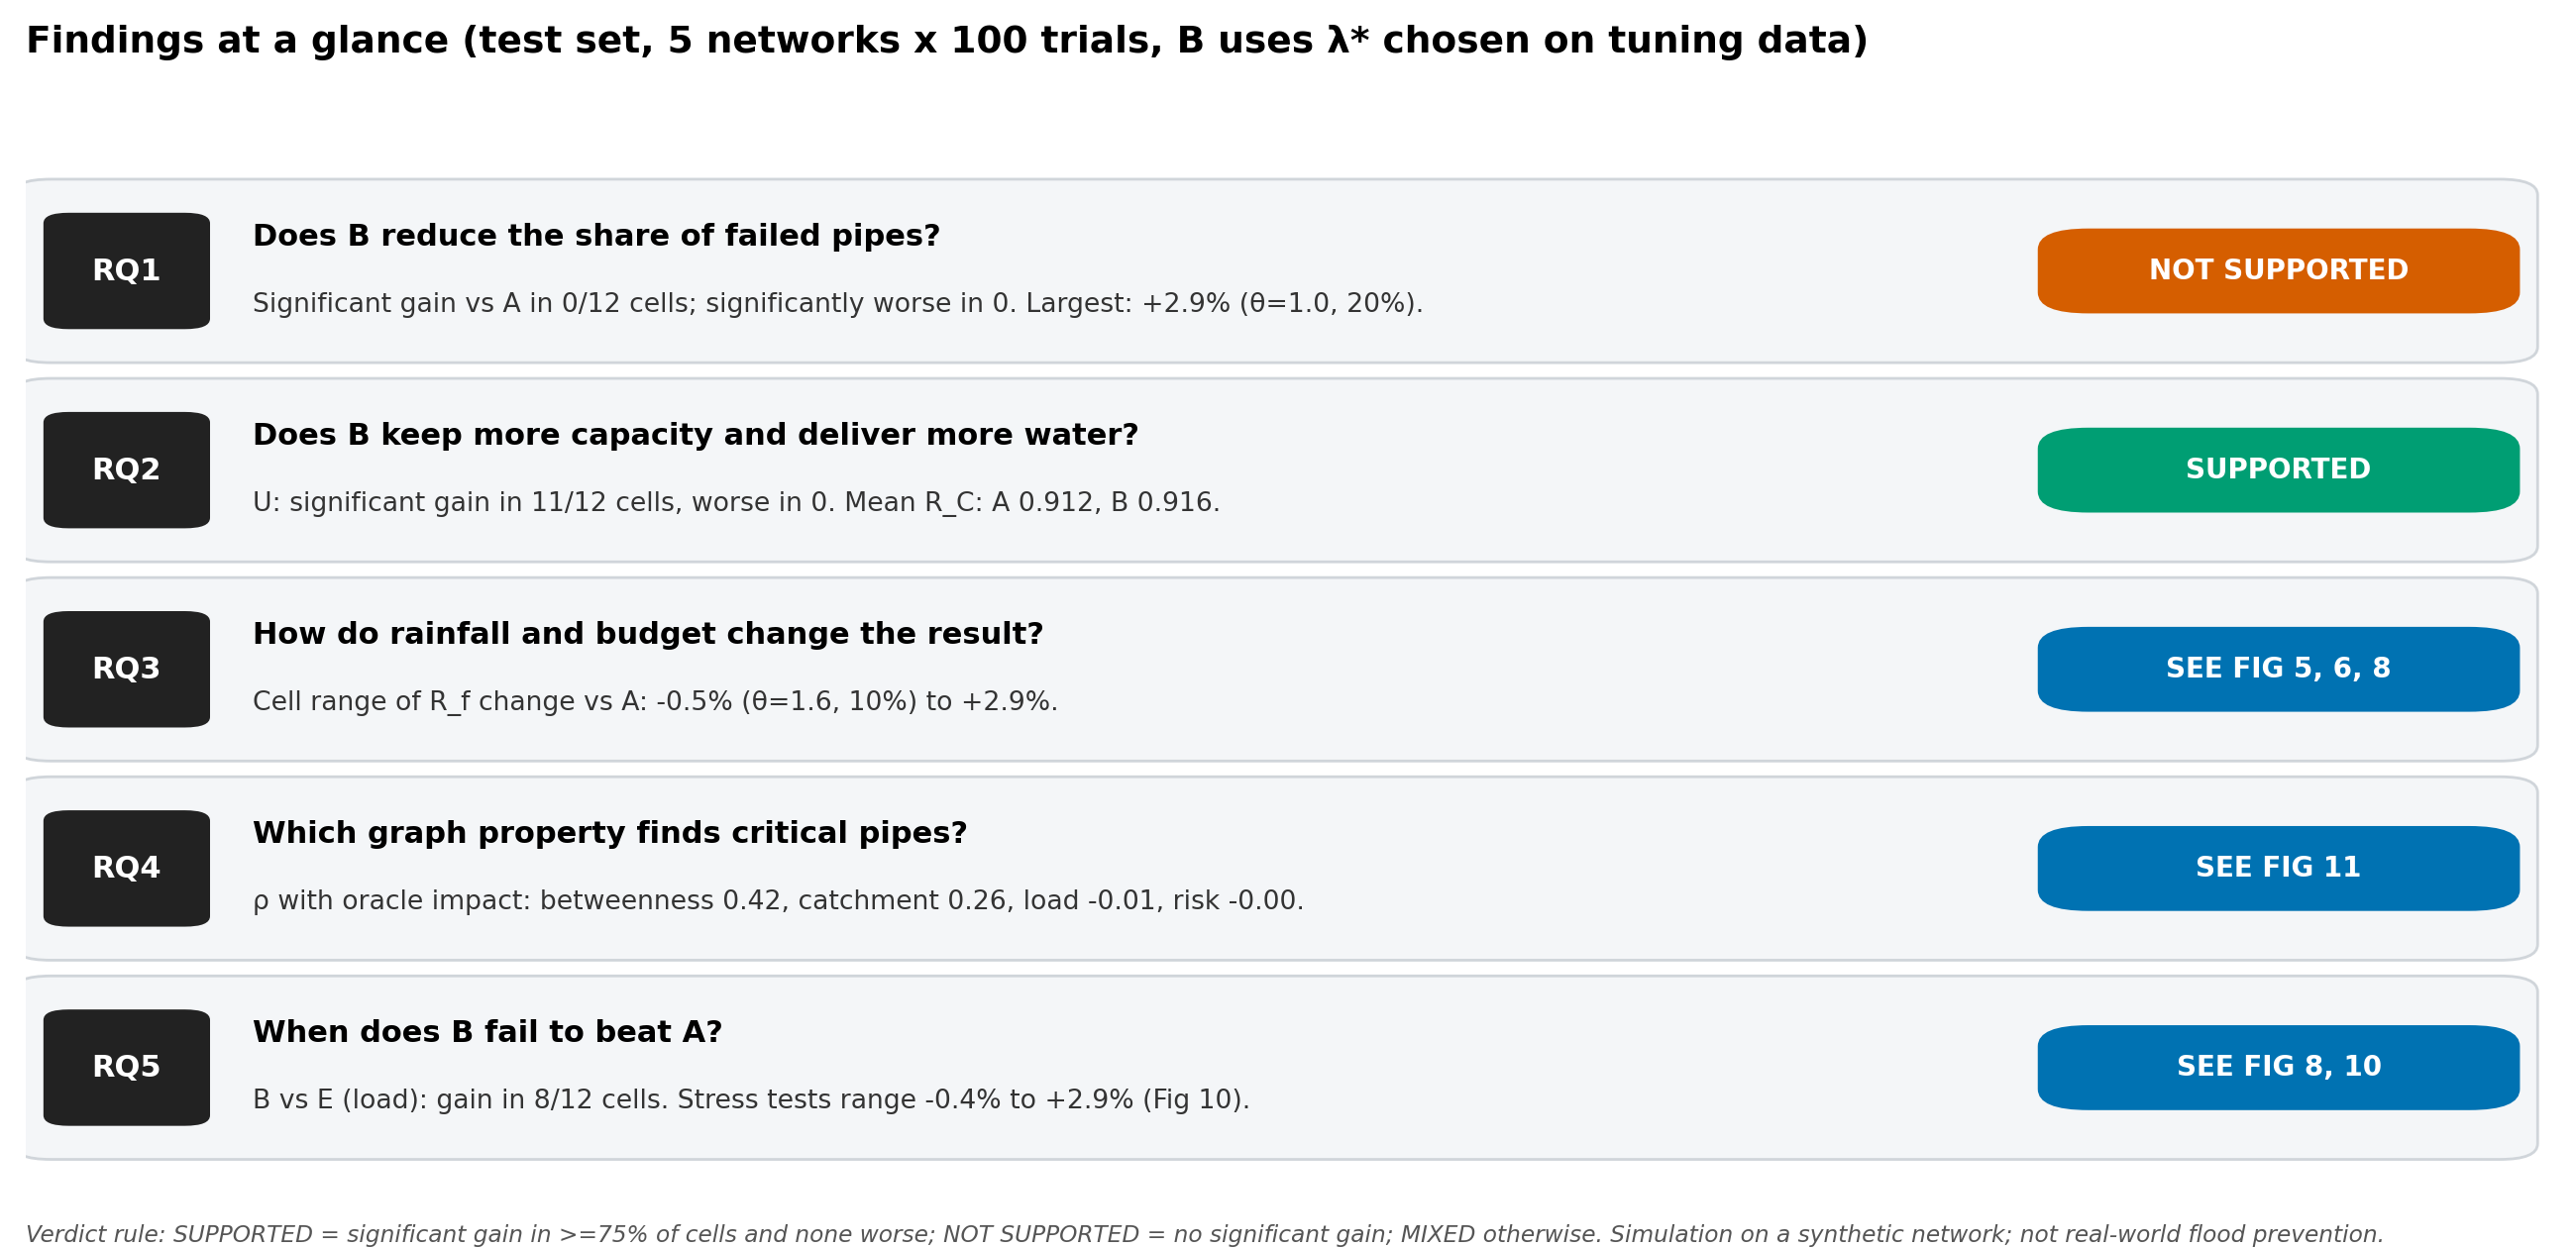

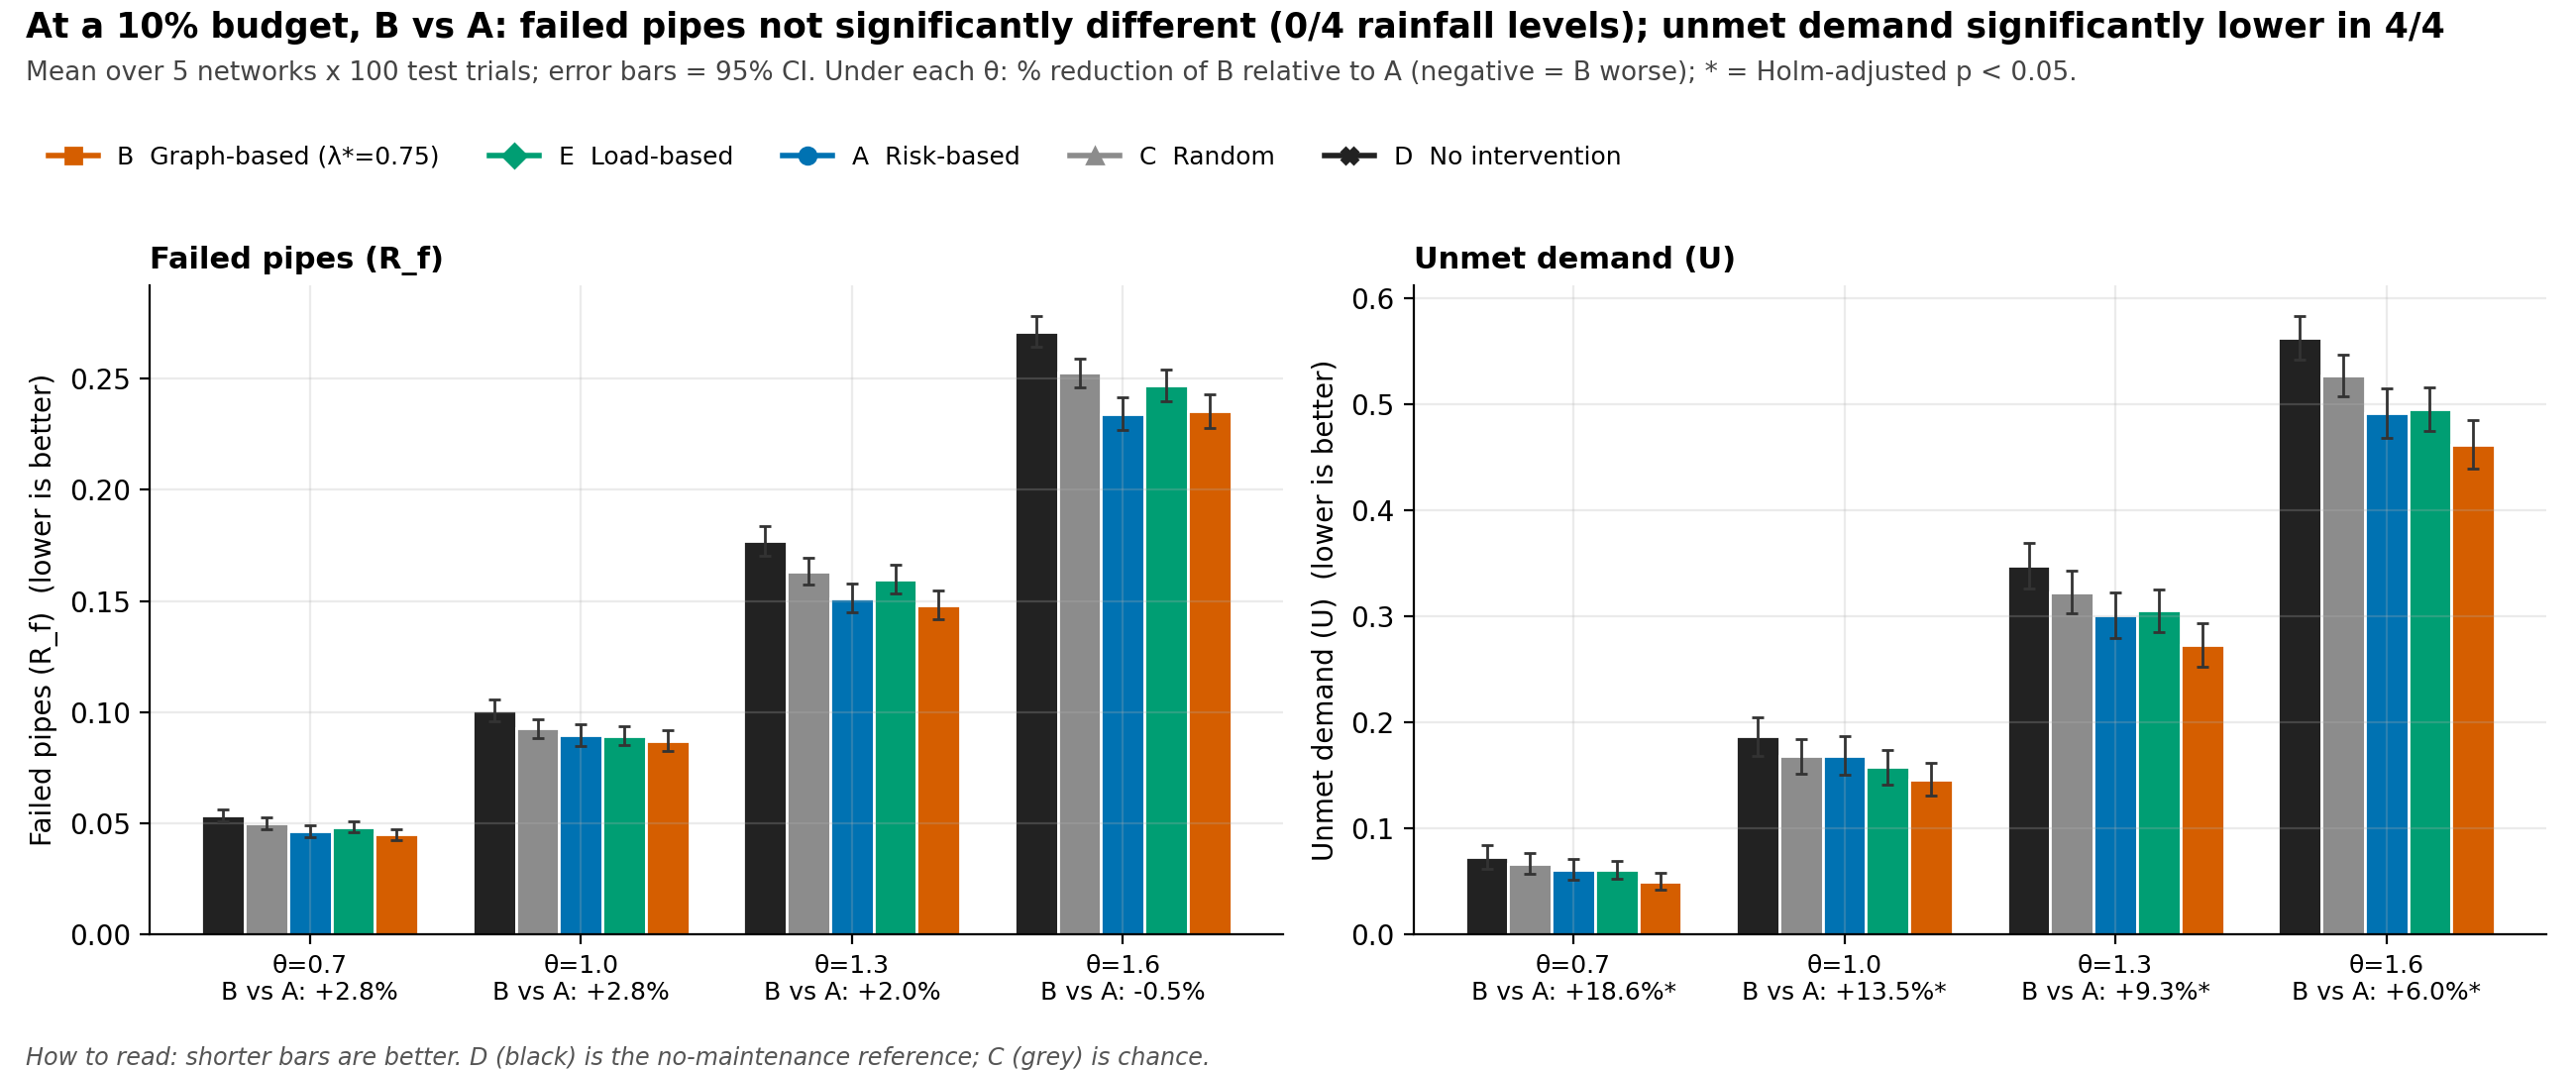

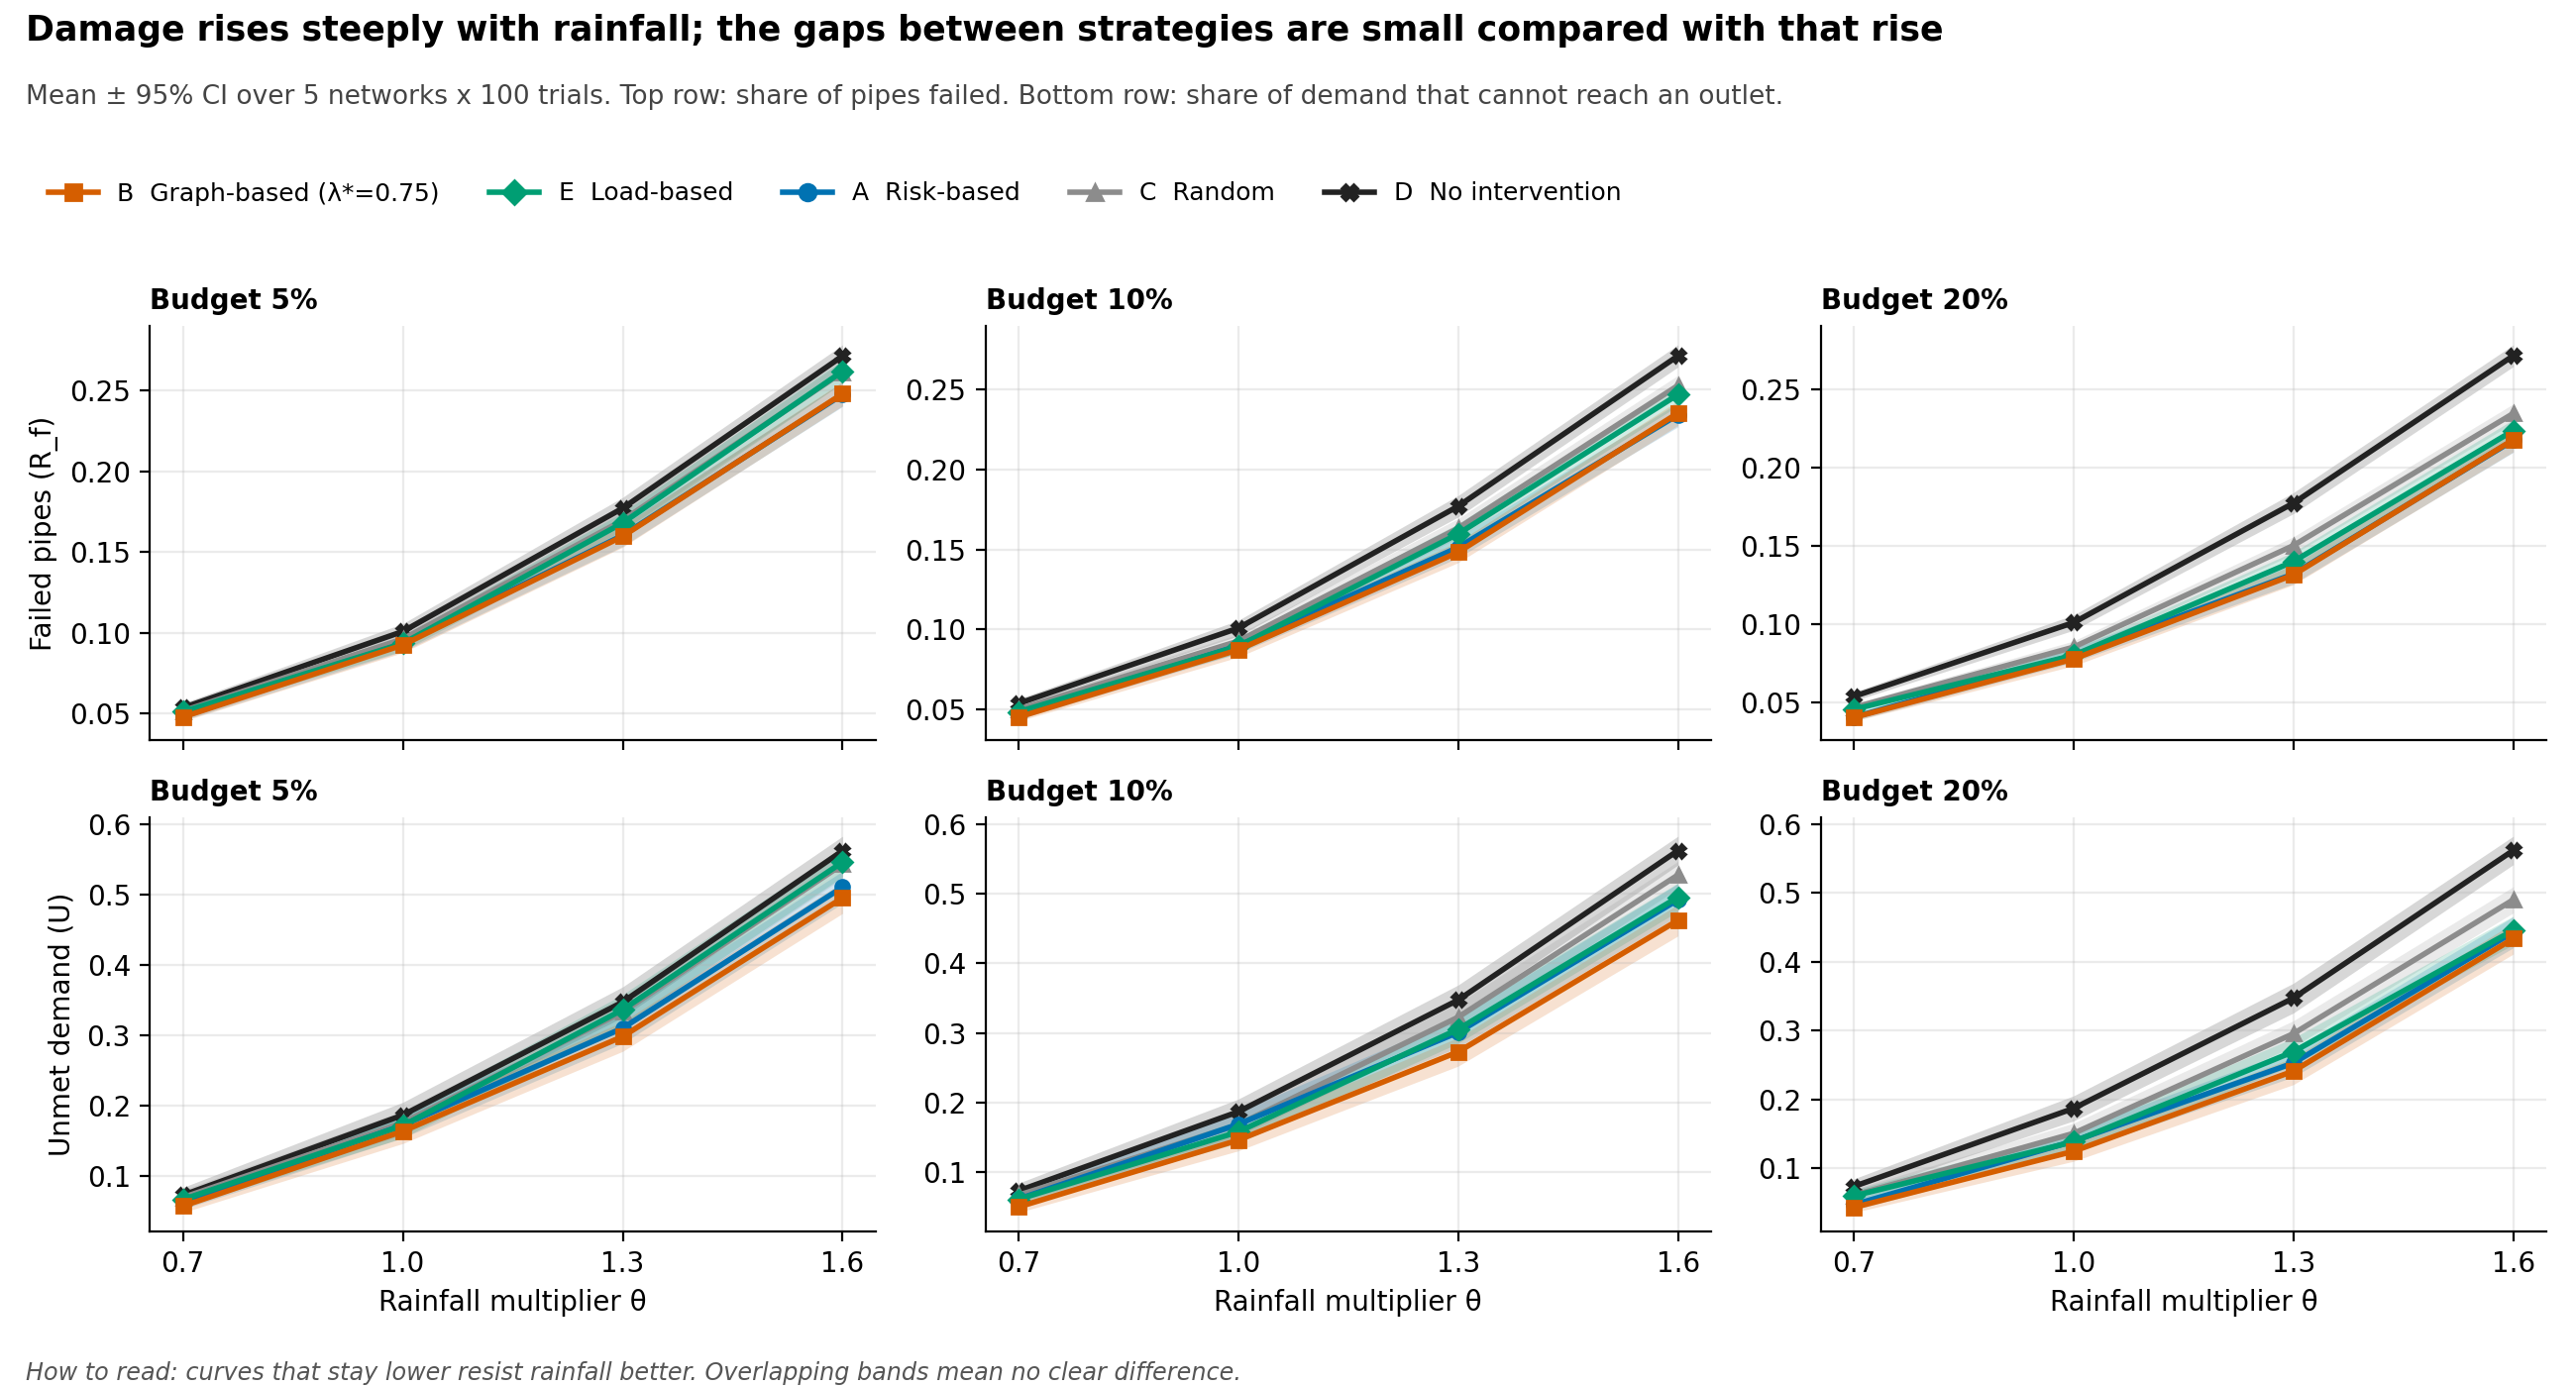

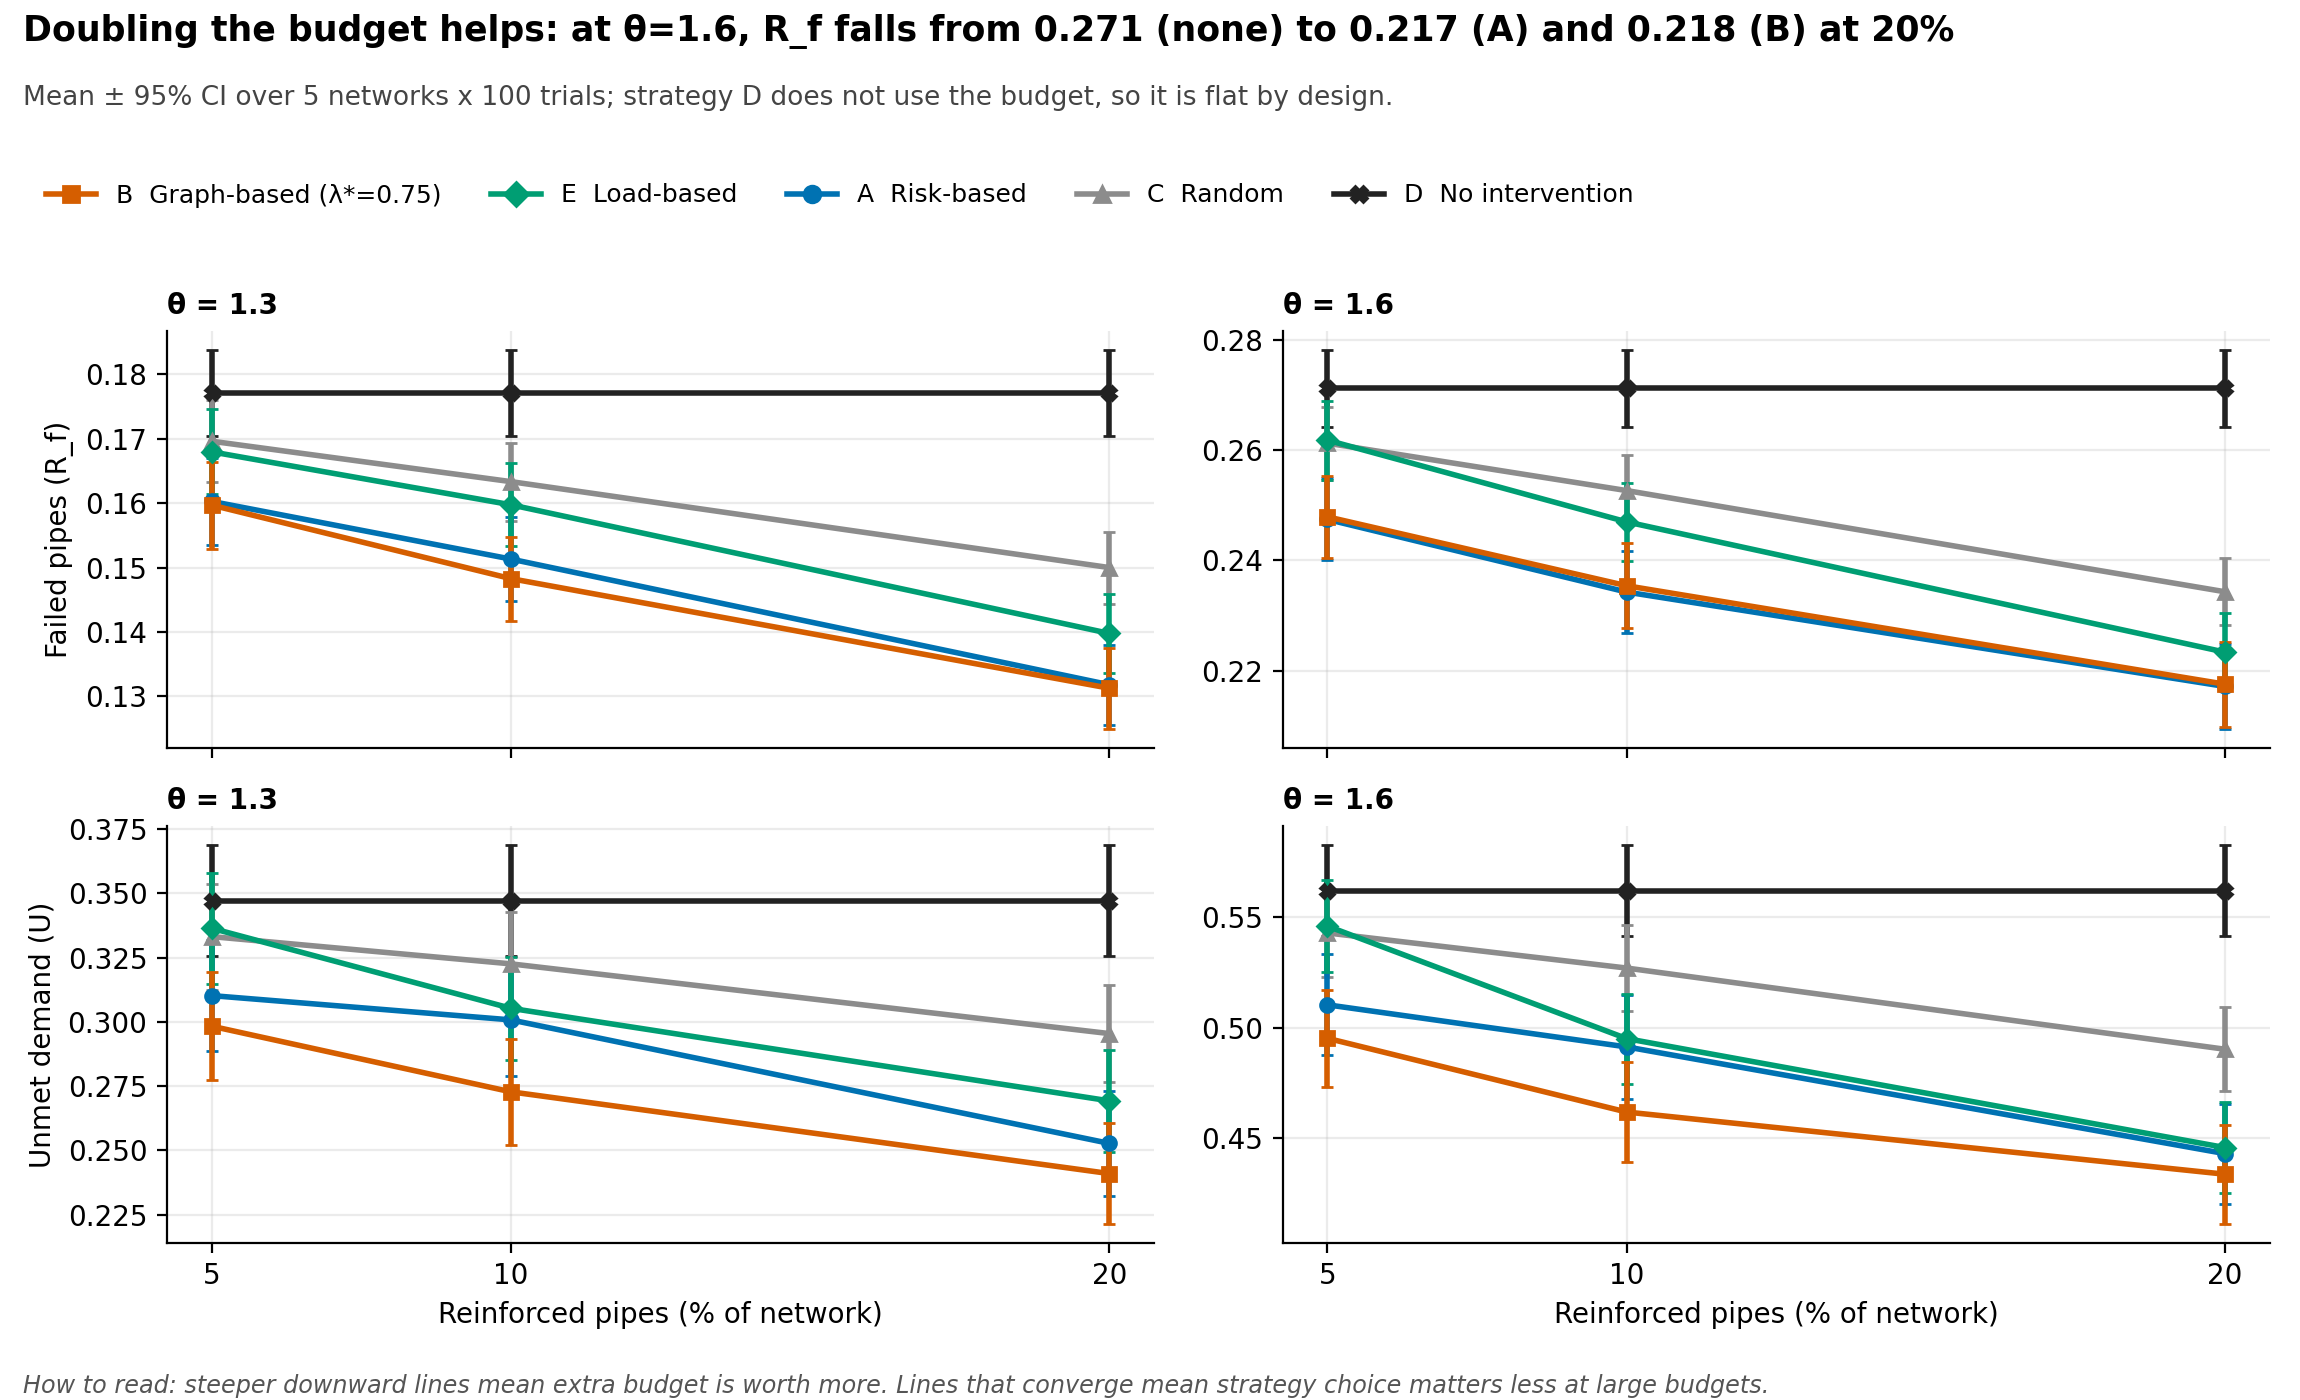

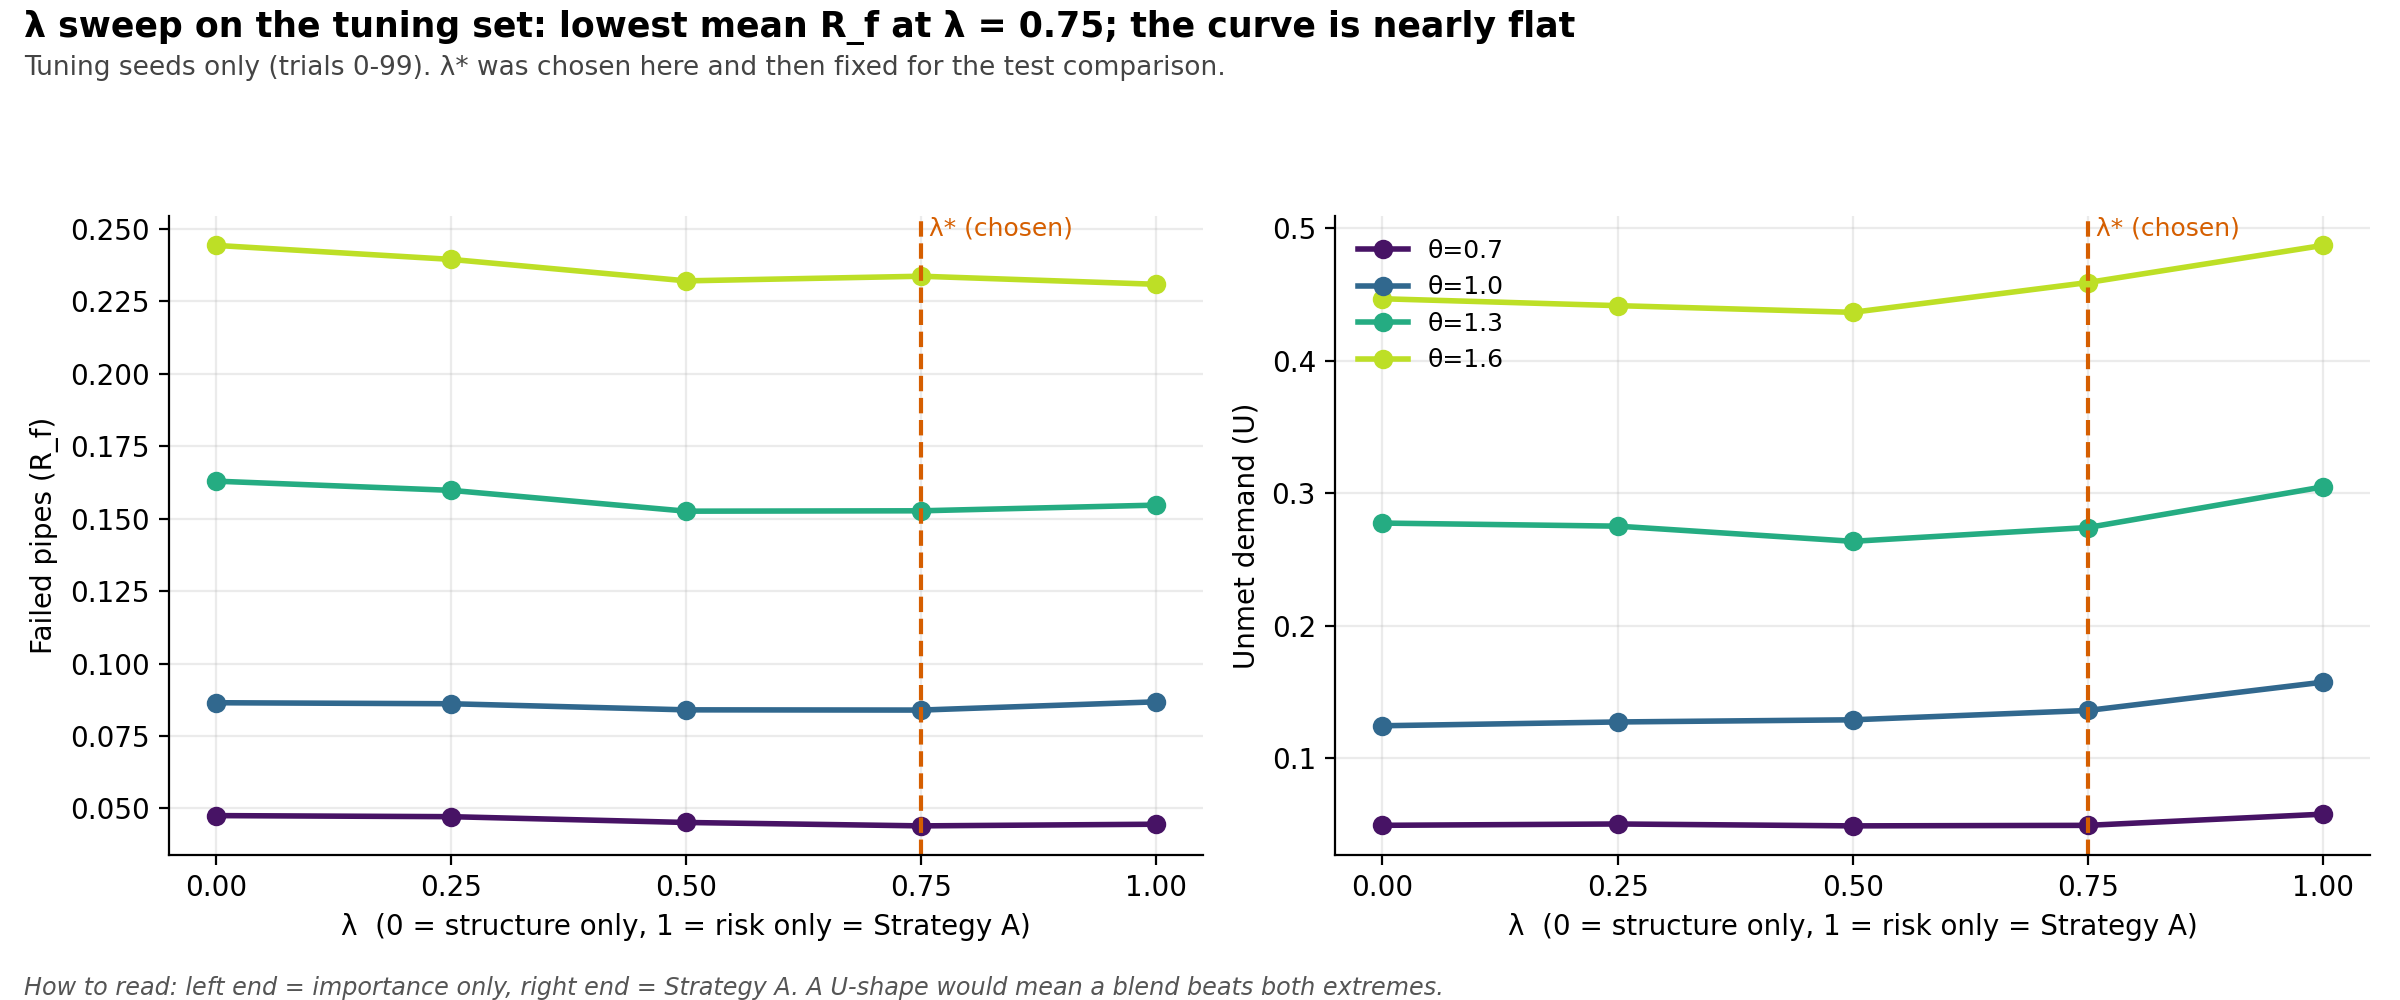

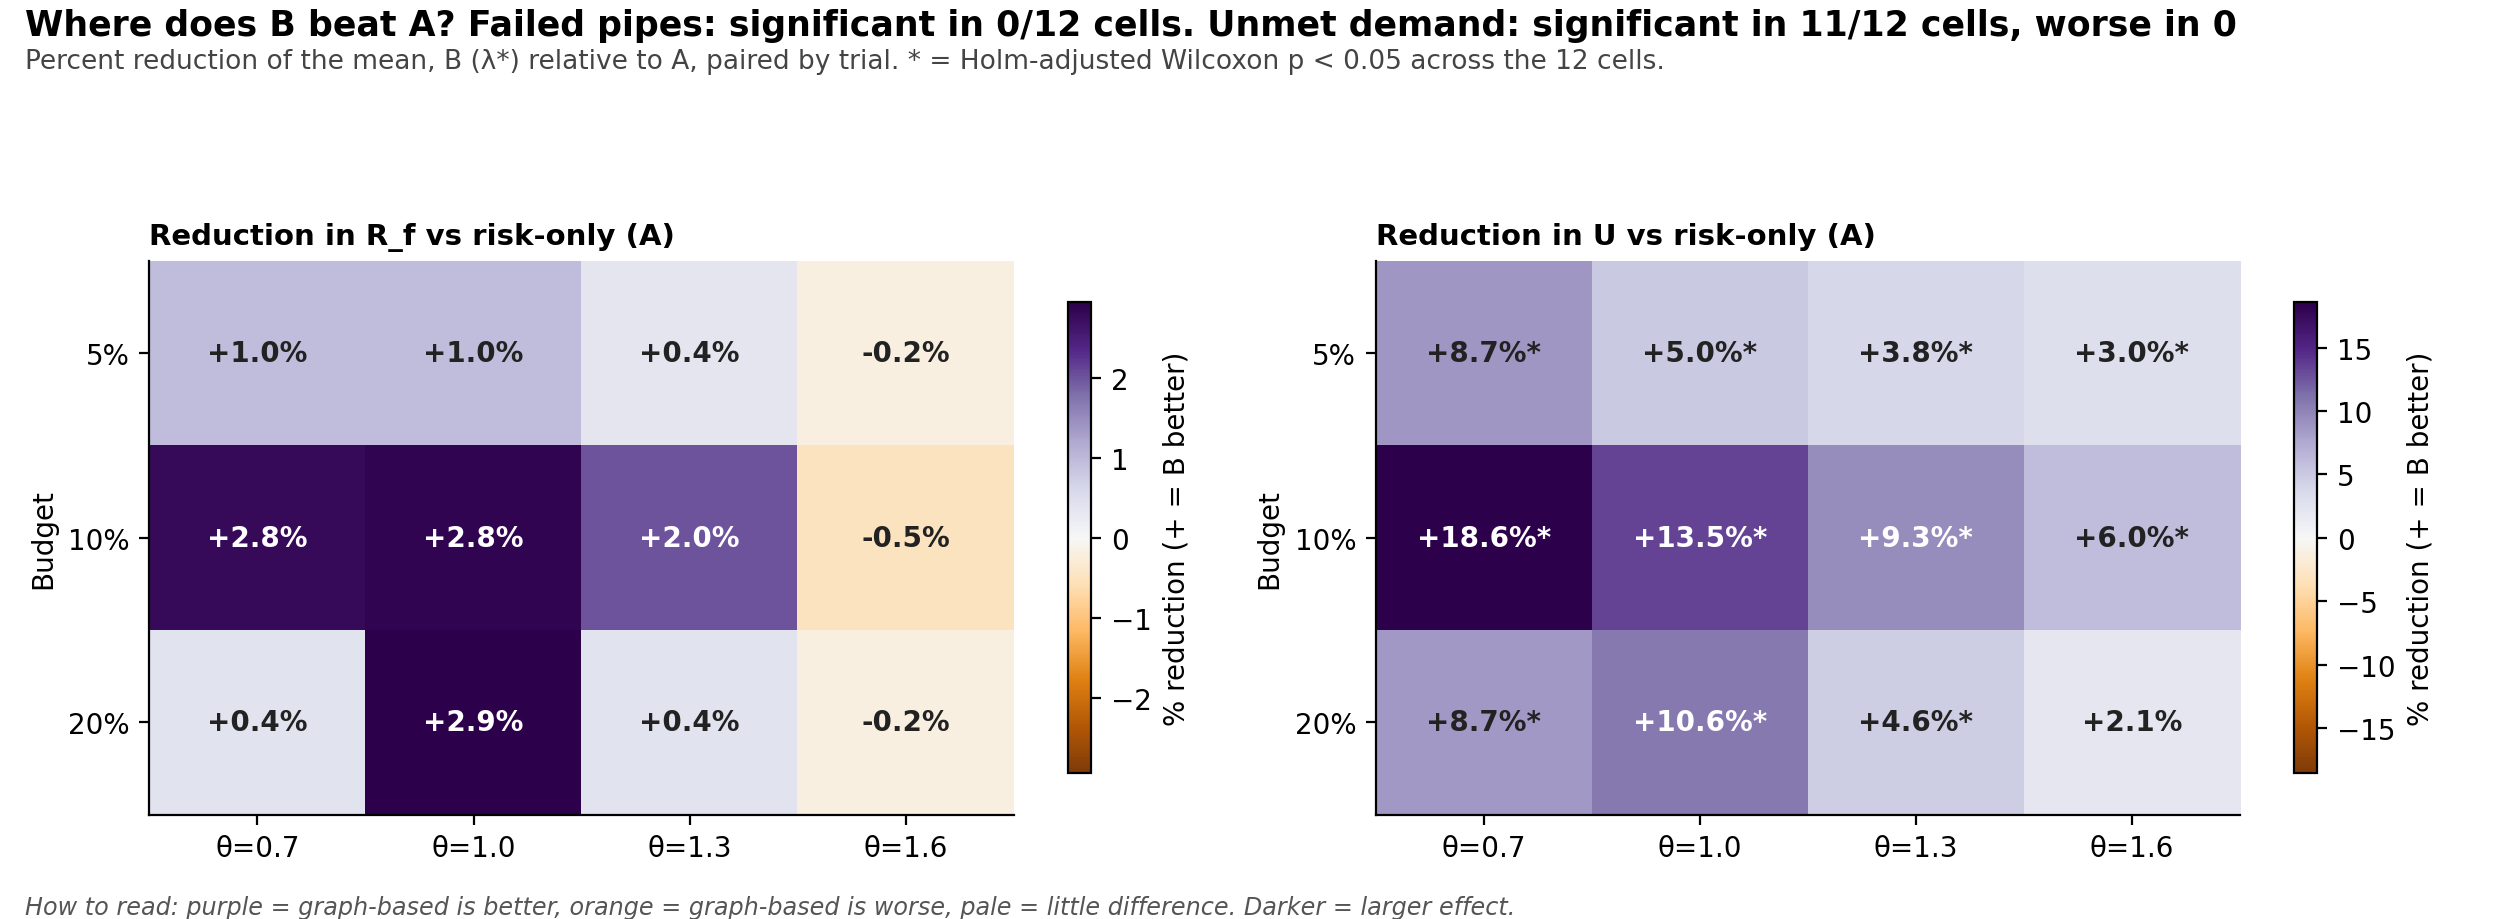

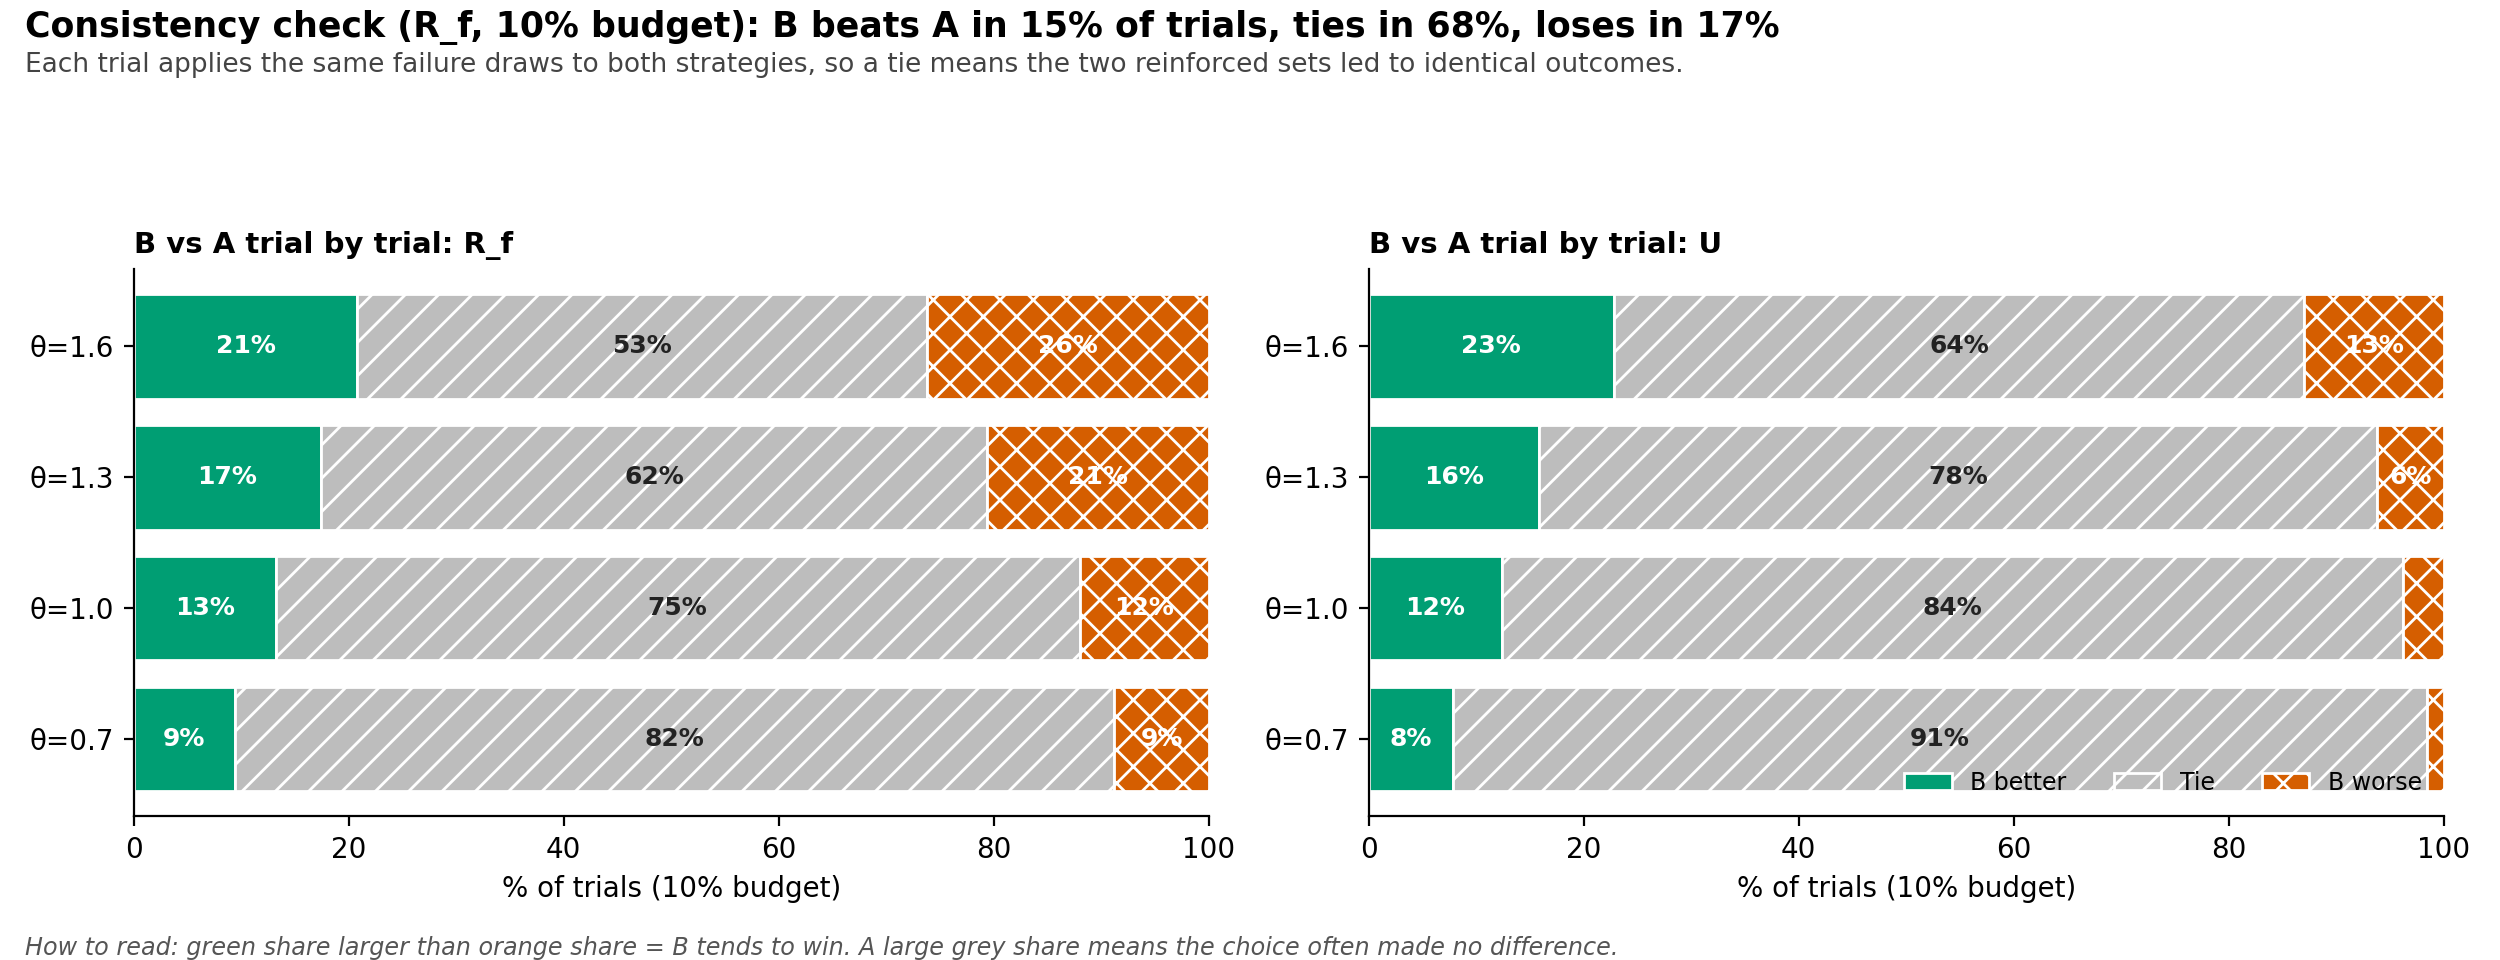

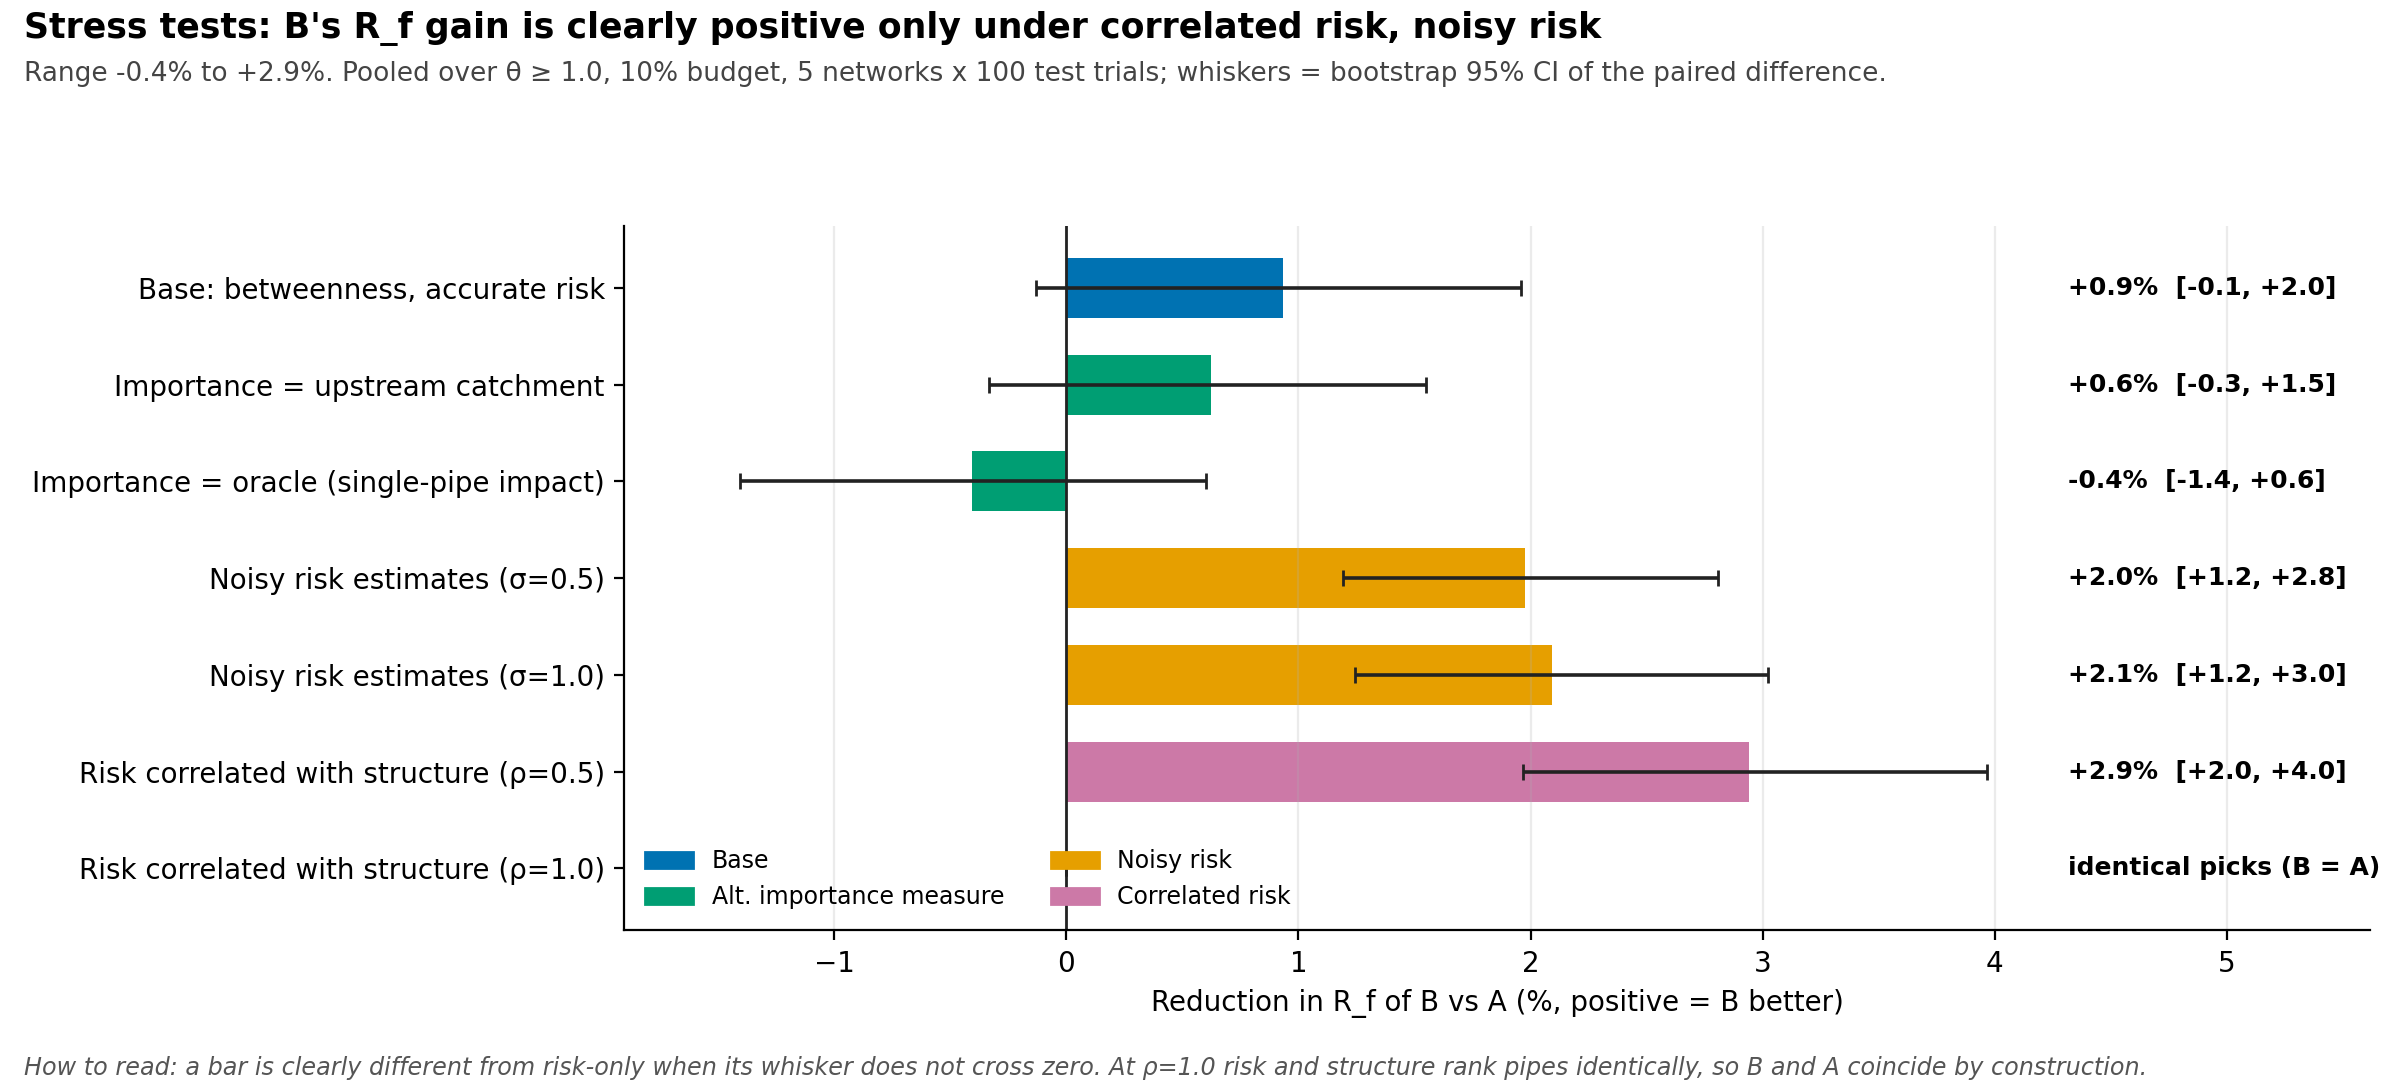

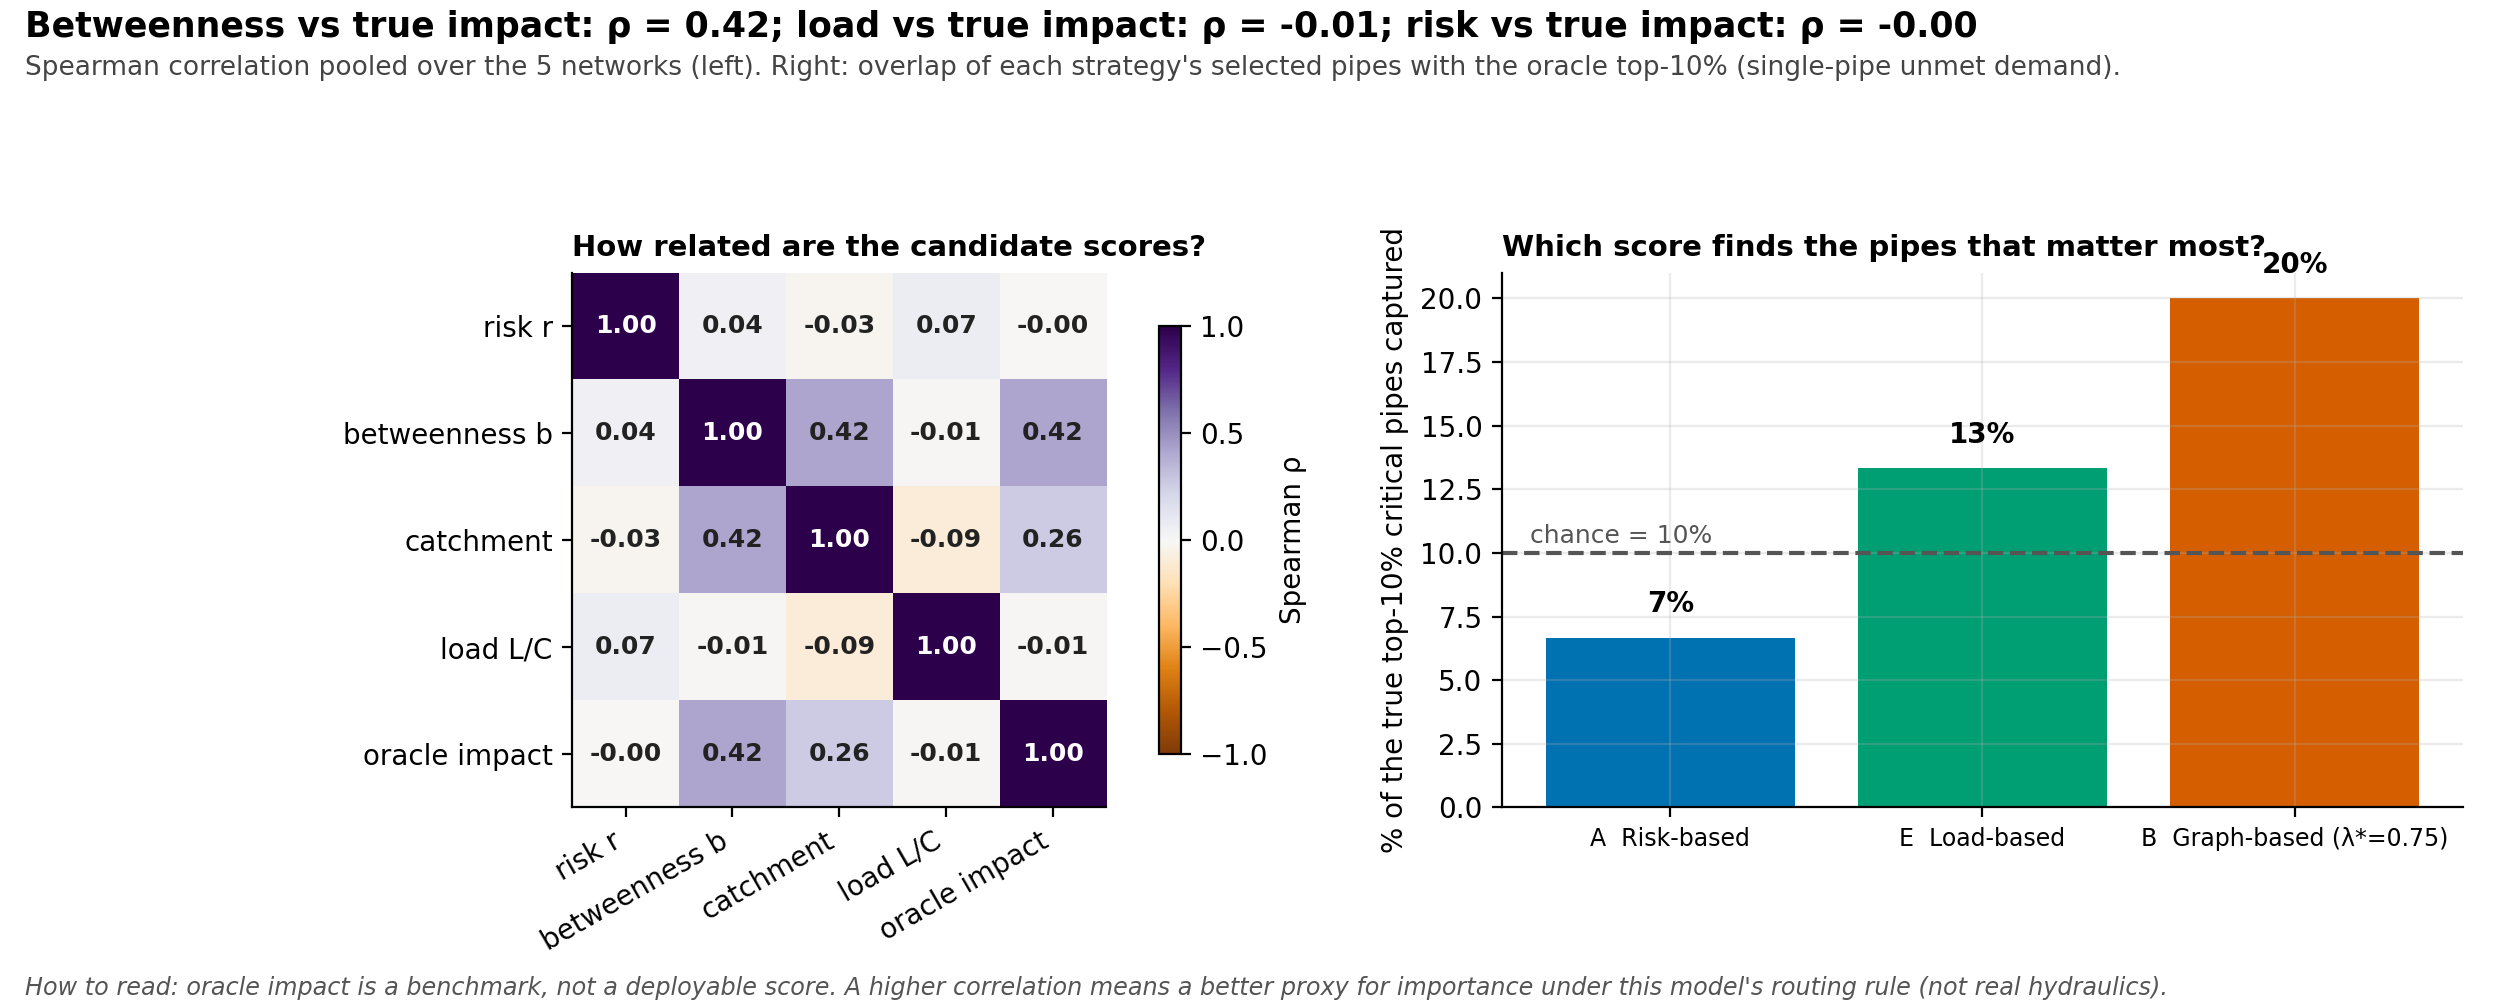

In [16]:
from IPython.display import Image, display
import glob
for f in ['fig0_scorecard','fig4_headline_comparison','fig5_rainfall_response','fig6_budget_response','fig7_lambda_sweep','fig8_reduction_heatmap','fig9_win_tie_loss','fig10_stress_tests','fig11_proxy_quality']:
    display(Image(f'results/figs/{f}.png'))

In [17]:
import pandas as pd
for f in ['paired_B_vs_A_Rf','paired_B_vs_A_U','T4_stress_tests','T5_spearman']:
    print('\n', f); display(pd.read_csv(f'results/tables/{f}.csv'))


 paired_B_vs_A_Rf


,theta,budget,mean_ref,mean_target,mean_diff,ci_lo,ci_hi,reduction_pct,p_raw,n,p_holm
0,0.7,0.05,0.04831,0.04785,0.00046,-0.00034,0.00150,0.95442,0.26915,500,1.00000
1,0.7,0.10,0.04633,0.04504,0.00129,0.00032,0.00244,2.78194,0.11838,500,1.00000
2,0.7,0.20,0.04035,0.04020,0.00016,-0.00041,0.00076,0.39301,0.94364,500,1.00000
3,1.0,0.05,0.09330,0.09240,0.00090,-0.00027,0.00228,0.96181,0.58679,500,1.00000
4,1.0,0.10,0.08974,0.08719,0.00256,0.00092,0.00431,2.84731,0.07374,500,0.73744
5,1.0,0.20,0.07985,0.07750,0.00235,0.00092,0.00390,2.93804,0.01303,500,0.15633
6,1.3,0.05,0.16026,0.15968,0.00057,-0.00080,0.00220,0.35780,0.49860,500,1.00000
7,1.3,0.10,0.15131,0.14828,0.00303,0.00037,0.00585,2.00562,0.53621,500,1.00000
8,1.3,0.20,0.13181,0.13127,0.00054,-0.00146,0.00260,0.40800,0.36579,500,1.00000
9,1.6,0.05,0.24744,0.24791,-0.00047,-0.00248,0.00179,-0.18919,0.06002,500,0.66019



 paired_B_vs_A_U


,theta,budget,mean_ref,mean_target,mean_diff,ci_lo,ci_hi,reduction_pct,p_raw,n,p_holm
0,0.7,0.05,0.06308,0.05757,0.00551,0.00162,0.01069,8.72944,0.00375,500,0.00905
1,0.7,0.10,0.06127,0.04989,0.01137,0.00678,0.01729,18.56571,0.00000,500,0.00000
2,0.7,0.20,0.04660,0.04255,0.00404,0.00164,0.00690,8.67800,0.00009,500,0.00054
3,1.0,0.05,0.17247,0.16385,0.00861,0.00355,0.01490,4.99381,0.00009,500,0.00054
4,1.0,0.10,0.16874,0.14601,0.02273,0.01491,0.03121,13.47309,0.00000,500,0.00000
5,1.0,0.20,0.13908,0.12432,0.01476,0.00820,0.02180,10.61038,0.00000,500,0.00000
6,1.3,0.05,0.31026,0.29835,0.01191,0.00602,0.01887,3.83914,0.00010,500,0.00054
7,1.3,0.10,0.30081,0.27281,0.02800,0.01833,0.03757,9.30887,0.00000,500,0.00000
8,1.3,0.20,0.25275,0.24100,0.01174,0.00458,0.01958,4.64633,0.00302,500,0.00905
9,1.6,0.05,0.51041,0.49526,0.01515,0.00919,0.02187,2.96805,0.00000,500,0.00000



 T4_stress_tests


,condition,family,red,lo,hi
0,"Base: betweenness, accurate risk",Base,0.936,-0.132,1.959
1,Importance = upstream catchment,Alt. importance measure,0.626,-0.330,1.549
2,Importance = oracle (single-pipe impact),Alt. importance measure,-0.404,-1.403,0.603
3,Noisy risk estimates (σ=0.5),Noisy risk,1.975,1.193,2.809
4,Noisy risk estimates (σ=1.0),Noisy risk,2.094,1.243,3.022
5,Risk correlated with structure (ρ=0.5),Correlated risk,2.942,1.966,3.966
6,Risk correlated with structure (ρ=1.0),Correlated risk,0.000,0.000,0.000



 T5_spearman


,Unnamed: 0,risk r,betweenness b,catchment,load L/C,oracle impact
0,risk r,1.000,0.040,-0.028,0.067,-0.002
1,betweenness b,0.040,1.000,0.415,-0.010,0.418
2,catchment,-0.028,0.415,1.000,-0.092,0.264
3,load L/C,0.067,-0.010,-0.092,1.000,-0.010
4,oracle impact,-0.002,0.418,0.264,-0.010,1.000
